# H&M Design & Demand Intelligence — Colab backend

**What this notebook is.** The backend of a two-sided fashion intelligence tool, running entirely in Google Colab on **real data**:

| Source | What it gives | How it gets here |
|---|---|---|
| **H&M Personalized Fashion Recommendations** (Kaggle) | 31M real H&M transactions (Sep 2018 – Sep 2020), 105k articles with colour, pattern and product descriptions, 1.4M customers with age | Kaggle API |
| **Google Trends** | Monthly worldwide search interest for ~25 fashion keywords (2018 → today) | `pytrends` |
| **Pantone** | Colour of the Year 2026 and the NYFW Autumn/Winter 2026 and Spring/Summer 2027 colour trend reports | Curated table (cell 6) |
| **Customer votes** | Ratings, colour picks and price answers from shoppers who tap the voting link on an Instagram post | Google Sheet (filled by the voting page) |

**The two sides of the venture**
1. **Business side** (designers, merchandisers, inventory planners): what to design, why, how many to make, when to launch. Shown on a plain business dashboard.
2. **Customer side**: H&M posts a design on Instagram → shoppers tap a link → rate the piece, pick a colour, say if they'd buy at the price. Their votes land in the Google Sheet and feed back into this notebook's scoring.

```text
 Kaggle H&M sales ─┐
 Google Trends ────┼──► this notebook ──► Google Sheet ──► business dashboard
 Pantone palettes ─┤   (ML models)          ▲   │
 Customer votes ───┘                        │   └──► voting page ◄── Instagram link
                                            └────────── votes ◄────────┘
```

**Machine learning in this notebook:** sales and correlation heatmaps · trend seasonality decomposition and damped projection · trend-lifecycle clustering (k-means + silhouette) · four demand models compared on a time-based holdout and time-series cross-validation · permutation importance and partial dependence · a "hit" classifier (logistic regression vs random forest vs gradient boosting; ROC, confusion matrix) · product style clustering (k-means + PCA) · newsvendor stock optimisation on simulated demand · Bayesian-style (Wilson) scoring of customer votes.

> Independent concept project, not affiliated with or endorsed by H&M. The Kaggle dataset was released by H&M Group for a public competition; its prices are anonymised, so euro prices in the briefs are assumptions.

**Run order:** `Runtime → Run all`. First run takes ~15–20 min (downloads ~4 GB and aggregates 31M rows); later runs use the cached aggregates in Google Drive and take a few minutes.

## 1. Setup and settings
Edit the settings in the next cell. The only one you must fill in is `SHEET_URL` (the Google Sheet that connects the voting page and the business dashboard). Leave it empty to run the analysis without the Sheet.

In [27]:
import sys, os, re, json, math, time, hashlib, subprocess, warnings
from datetime import date, datetime, timedelta
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytrends", "kaggle", "python-docx", "google-genai"], check=False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# ─── Settings ────────────────────────────────────────────────────────────────
SHEET_URL = "https://docs.google.com/spreadsheets/d/1R2hWWyeWgMYycOZBYHRMcXD_JbRFpjy2d9IpNQZQUTE/edit"  # your Sheet in Drive
USE_DRIVE = True          # cache raw files and aggregates in Google Drive so reruns are fast
REBUILD_AGGREGATES = False  # True = re-read the 31M transactions even if a cache exists
REFRESH_TRENDS = False    # True = re-download Google Trends even if a cache exists
GENERATE_IMAGES = True    # AI concept photos for the voting page (needs a GEMINI_API_KEY Colab secret; see section 12b)

AS_OF = date.fromisoformat(os.getenv("AS_OF", date.today().isoformat()))
LEAD_TIME_WEEKS = 12      # design-to-store lead time
SELL_WEEKS = 12           # selling window the demand model forecasts
GARMENTS = ["dress", "top", "jeans", "skirt"]
BRIEFS_PER_GARMENT = 3
MIN_MULTIWAY = 4          # at least this many of the 12 briefs are convertible
MIN_SUSTAINABLE = 4       # at least this many use a sustainable material
RANDOM_SEED = 42
PANEL_TO_STORE_MULTIPLIER = 1.0  # Kaggle data covers H&M's sampled customer panel; scale units up if needed

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/hm_design_intelligence")
else:
    PROJECT_DIR = Path(os.getenv("HM_PROJECT_DIR", "hm_design_intelligence"))
RAW_DIR, CACHE_DIR, OUT_DIR = PROJECT_DIR / "raw", PROJECT_DIR / "cache", PROJECT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
for d in (RAW_DIR, CACHE_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

REPORT_FIGS: dict[str, tuple] = {}   # about → (chart file, how), collected for the Word report (section 16)


def note(about: str, how: str) -> None:
    """Print what a chart or table shows and how it was made, right under it."""
    text = f"**What it shows:** {about}  \n**How we made it:** {how}"
    try:
        from IPython.display import Markdown
        display(Markdown(text))
    except Exception:
        print(text.replace("**", "").replace("  \n", "\n"))


def show_fig(about: str, how: str) -> None:
    """Show the current chart with its explanation, and keep a high-resolution copy for the report."""
    fig = plt.gcf()
    fig.tight_layout()
    path = FIG_DIR / f"chart_{hashlib.md5(about.encode()).hexdigest()[:8]}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    REPORT_FIGS[about] = (path, how)
    plt.show()
    note(about, how)


LAUNCH_DATE = AS_OF + timedelta(weeks=LEAD_TIME_WEEKS)
LAUNCH_WEEK = LAUNCH_DATE - timedelta(days=LAUNCH_DATE.weekday())
rng = np.random.default_rng(RANDOM_SEED)
print(f"As of {AS_OF} · briefs launch w/c {LAUNCH_WEEK} · files in {PROJECT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
As of 2026-11-07 · briefs launch w/c 2027-01-25 · files in /content/drive/MyDrive/hm_design_intelligence


## 2. Download the real H&M data from Kaggle
One-time setup:
1. Create a free Kaggle account, open the [competition rules page](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/rules) and click **I Understand and Accept** (downloads are refused until you do).
2. Kaggle → Settings → **Create New Token** downloads `kaggle.json`.
3. Either add `KAGGLE_USERNAME` and `KAGGLE_KEY` as Colab **Secrets** (🔑 icon on the left), or upload `kaggle.json` when this cell asks.

Only three files are downloaded (not the 30 GB of images).

In [28]:
COMPETITION = "h-and-m-personalized-fashion-recommendations"
RAW_FILES = ["articles.csv", "customers.csv", "transactions_train.csv"]
AGG_FILES = [CACHE_DIR / f for f in ("articles.pkl", "weekly_units.pkl", "age_units.pkl")]
have_cache = all(p.exists() for p in AGG_FILES) and not REBUILD_AGGREGATES


def setup_kaggle_credentials() -> None:
    if os.getenv("KAGGLE_USERNAME") and os.getenv("KAGGLE_KEY"):
        return
    if (Path.home() / ".kaggle" / "kaggle.json").exists():
        return
    if IN_COLAB:
        try:
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
            return
        except Exception:
            pass
        from google.colab import files
        print("Upload your kaggle.json:")
        uploaded = files.upload()
        kdir = Path.home() / ".kaggle"
        kdir.mkdir(exist_ok=True)
        (kdir / "kaggle.json").write_bytes(uploaded["kaggle.json"])
        os.chmod(kdir / "kaggle.json", 0o600)


def download_raw() -> None:
    missing = [f for f in RAW_FILES if not (RAW_DIR / f).exists()]
    if not missing:
        return
    setup_kaggle_credentials()
    for name in missing:
        print(f"Downloading {name} …")
        res = subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-f", name, "-p", str(RAW_DIR)],
                             capture_output=True, text=True)
        if res.returncode != 0:
            raise RuntimeError(
                f"Kaggle download failed for {name}:\n{res.stderr or res.stdout}\n"
                "→ Did you accept the competition rules? (link in the cell above)")
        zipped = RAW_DIR / f"{name}.zip"
        if zipped.exists():
            subprocess.run(["unzip", "-o", "-q", str(zipped), "-d", str(RAW_DIR)], check=True)
            zipped.unlink()


if have_cache:
    print("Using cached aggregates — skipping the raw download.")
else:
    download_raw()
    print("Raw files ready:", [f"{f} ({(RAW_DIR / f).stat().st_size / 1e6:,.0f} MB)" for f in RAW_FILES])

Using cached aggregates — skipping the raw download.


## 3. Prepare products: garment type and design attributes
We keep women's pieces (Ladieswear and Divided) in the four garment types the tool designs for. Design attributes that aren't columns in the data (silhouette, length, signature details, fabric, sustainable materials, convertible features) are extracted from H&M's own product names and descriptions with text rules.

In [29]:
ATTRIBUTE_RULES = {
    # silhouettes
    "silhouette:wide": r"\bwide\b", "silhouette:skinny": r"\bskinny\b", "silhouette:slim": r"\bslim\b",
    "silhouette:straight": r"\bstraight\b", "silhouette:mom": r"\bmom\b", "silhouette:flare": r"\bflare",
    "silhouette:barrel": r"\bbarrel\b|\bballoon\b", "silhouette:wrap": r"\bwrap", "silhouette:a-line": r"a-line",
    "silhouette:fitted": r"\bfitted\b|bodycon", "silhouette:oversized": r"oversized|\bloose\b|relaxed",
    "silhouette:slip": r"\bslip\b",
    # lengths
    "length:mini": r"\bmini\b|short dress|short skirt", "length:midi": r"\bmidi\b|calf-length",
    "length:maxi": r"\bmaxi\b|ankle-length|long dress|long skirt", "length:cropped": r"\bcrop",
    # signature details
    "detail:puff-sleeve": r"puff(?:ed|y)? sleeve", "detail:ruffle": r"ruffle|frill|flounce",
    "detail:smocking": r"smock", "detail:slit": r"\bslit\b|\bsplit\b", "detail:pleats": r"pleat",
    "detail:lace": r"\blace\b", "detail:buttons": r"button", "detail:cut-out": r"cut-?out",
    "detail:tie": r"tie belt|ties? at|tie-top|\btie\b(?!-dye)", "detail:sheer": r"sheer|\bmesh\b",
    "detail:corset": r"corset|bustier|boned",
    # fabrics
    "fabric:denim": r"denim|\bjeans?\b", "fabric:linen": r"linen", "fabric:satin": r"satin|\bsilk",
    "fabric:jersey": r"jersey", "fabric:cotton": r"cotton", "fabric:viscose": r"viscose|cr[eê]pe",
    "fabric:knit": r"\bknit",
    # pattern
    "pattern:dot": r"\bdots?\b|polka|spot",
}
SUSTAINABLE_RE = r"recycled|organic|lyocell|tencel|conscious|repreve|econyl|lenzing"
MULTIWAY_RE = r"detachable|removable|convertible|reversible|can be worn|two ways|transformable|zip-off|adjustable straps?"
ATTRS = list(ATTRIBUTE_RULES)
TOP_TYPES = {"Top", "Blouse", "Vest top", "Bodysuit"}


def prepare_articles(raw: pd.DataFrame) -> pd.DataFrame:
    a = raw[raw["index_group_name"].isin(["Ladieswear", "Divided"])].copy()
    text = (a["prod_name"].fillna("") + " " + a["detail_desc"].fillna("")).str.lower()
    pt = a["product_type_name"]
    a["garment"] = np.select(
        [pt.eq("Dress"), pt.eq("Skirt"),
         pt.eq("Trousers") & (a["garment_group_name"].eq("Trousers Denim") | text.str.contains(r"\bjeans?\b")),
         pt.isin(TOP_TYPES)],
        ["dress", "skirt", "jeans", "top"], default="")
    a = a[a["garment"] != ""].copy()
    text = text.loc[a.index]
    for key, pattern in ATTRIBUTE_RULES.items():
        a[key] = text.str.contains(pattern, regex=True).astype(np.int8)
    a.loc[a["garment"].eq("jeans"), "fabric:denim"] = 1
    a["pattern:dot"] = (a["pattern:dot"] | a["graphical_appearance_name"].eq("Dot")).astype(np.int8)
    a["is_sustainable"] = text.str.contains(SUSTAINABLE_RE).astype(np.int8)
    a["is_multiway"] = text.str.contains(MULTIWAY_RE).astype(np.int8)
    a["is_solid"] = a["graphical_appearance_name"].isin(["Solid", "Melange", "Denim"]).astype(np.int8)
    a["colour"] = a["colour_group_name"]
    a["colour_family"] = a["perceived_colour_master_name"]
    keep = ["article_id", "prod_name", "product_type_name", "garment", "colour", "colour_family",
            "graphical_appearance_name", "is_solid", "is_sustainable", "is_multiway", *ATTRS]
    return a[keep].reset_index(drop=True)


if have_cache:
    articles = pd.read_pickle(AGG_FILES[0])
else:
    articles = prepare_articles(pd.read_csv(RAW_DIR / "articles.csv", dtype={"article_id": "int64"}))
print(f"{len(articles):,} women's articles in scope")
display(articles.groupby("garment").agg(articles=("article_id", "size"),
                                        sustainable=("is_sustainable", "mean"),
                                        convertible=("is_multiway", "mean")).style.format(
    {"sustainable": "{:.1%}", "convertible": "{:.1%}"}))

20,309 women's articles in scope


,articles,sustainable,convertible
garment,,,
dress,7860,7.4%,9.6%
jeans,1510,14.4%,1.9%
skirt,2293,5.7%,7.2%
top,8646,6.8%,2.1%


## 4. Aggregate 31 million transactions
Read in chunks (so it fits in Colab's memory) and keep only purchases of in-scope articles. Two aggregates are built and cached in Drive:
- **weekly units per article** (each transaction row = one unit sold),
- **units per article by customer age band** (who buys what).

In [30]:
AGE_BANDS = ["16-24", "25-34", "35-44", "45-54", "55+"]


def aggregate_transactions() -> tuple[pd.DataFrame, pd.DataFrame]:
    ids = set(articles["article_id"])
    cust = pd.read_csv(RAW_DIR / "customers.csv", usecols=["customer_id", "age"])
    band = pd.cut(cust["age"], [0, 24, 34, 44, 54, 120], labels=AGE_BANDS)
    age_map = dict(zip(cust["customer_id"], band.astype(object).where(band.notna(), "unknown")))
    del cust
    weekly_parts, age_parts, n_rows = [], [], 0
    reader = pd.read_csv(RAW_DIR / "transactions_train.csv",
                         usecols=["t_dat", "customer_id", "article_id", "price"],
                         dtype={"article_id": "int64", "price": "float32"}, chunksize=4_000_000)
    for i, chunk in enumerate(reader):
        n_rows += len(chunk)
        chunk = chunk[chunk["article_id"].isin(ids)]
        day = pd.to_datetime(chunk["t_dat"])
        chunk = chunk.assign(week=(day - pd.to_timedelta(day.dt.weekday, unit="D")).dt.normalize())
        weekly_parts.append(chunk.groupby(["article_id", "week"]).agg(units=("price", "size"), revenue=("price", "sum")))
        chunk = chunk.assign(age_band=chunk["customer_id"].map(age_map).fillna("unknown"))
        age_parts.append(chunk.groupby(["article_id", "age_band"]).size().rename("units"))
        print(f"  chunk {i + 1}: {n_rows:,} rows read")
    weekly = pd.concat(weekly_parts).groupby(level=[0, 1]).sum().reset_index()
    ages = pd.concat(age_parts).groupby(level=[0, 1]).sum().reset_index()
    print(f"{n_rows:,} transactions read; {weekly['units'].sum():,} in scope")
    return weekly, ages


if have_cache:
    weekly_units, age_units = pd.read_pickle(AGG_FILES[1]), pd.read_pickle(AGG_FILES[2])
else:
    weekly_units, age_units = aggregate_transactions()
    articles.to_pickle(AGG_FILES[0]); weekly_units.to_pickle(AGG_FILES[1]); age_units.to_pickle(AGG_FILES[2])

DATA_START, DATA_END = weekly_units["week"].min(), weekly_units["week"].max()
print(f"Sales history: {DATA_START:%d %b %Y} → {DATA_END:%d %b %Y}, {weekly_units['units'].sum():,} units")

Sales history: 17 Sep 2018 → 21 Sep 2020, 10,066,095 units


### Launch-level table
A product's **launch week** is its first week with sales. Products already selling in the first 8 weeks of the data are excluded (we can't see their real launch), as are products launched too late to have a full 12-week selling window. Every product then gets exactly 12 weekly rows (weeks with no sales = 0 units).

In [31]:
first_week = weekly_units.groupby("article_id")["week"].min().rename("launch_week")
price = (weekly_units.groupby("article_id")["revenue"].sum() / weekly_units.groupby("article_id")["units"].sum()).rename("price")
products = articles.merge(first_week, on="article_id").merge(price, on="article_id")
products = products[(products["launch_week"] >= DATA_START + pd.Timedelta(weeks=8))
                    & (products["launch_week"] <= DATA_END - pd.Timedelta(weeks=SELL_WEEKS - 1))].copy()
products["price_rel"] = products["price"] / products.groupby("garment")["price"].transform("median")

panel = products[["article_id", "launch_week"]].loc[products.index.repeat(SELL_WEEKS)].reset_index(drop=True)
panel["weeks_since_launch"] = np.tile(np.arange(SELL_WEEKS), len(products))
panel["week"] = panel["launch_week"] + pd.to_timedelta(panel["weeks_since_launch"] * 7, unit="D")
panel = panel.merge(weekly_units[["article_id", "week", "units"]], on=["article_id", "week"], how="left")
panel["units"] = panel["units"].fillna(0).astype(float)

totals = panel.groupby("article_id")["units"].sum().rename("units_12w")
first8 = panel[panel["weeks_since_launch"] < 8].groupby("article_id")["units"].sum().rename("units_8w")
products = products.merge(totals, on="article_id").merge(first8, on="article_id")
products["sell_index"] = products["units_12w"] / products.groupby("garment")["units_12w"].transform("mean")
print(f"{len(products):,} launches with a full 12-week window → {len(panel):,} product-week rows")
display(products.groupby("garment")[["units_12w", "price_rel"]].describe().round(2))

11,740 launches with a full 12-week window → 140,880 product-week rows


units_12w                                                   price_rel                                          
            count    mean     std  min    25%    50%    75%     max     count  mean   std   min   25%  50%   75%    max
garment                                                                                                                
dress      4899.0  345.37  412.99  1.0   73.0  203.0  471.0  3720.0    4899.0  1.19  0.89  0.07  0.72  1.0  1.39  12.82
jeans       693.0  411.95  511.45  1.0  121.0  243.0  546.0  6798.0     693.0  1.00  0.35  0.29  0.69  1.0  1.29   2.06
skirt      1404.0  307.86  308.12  1.0   86.0  218.5  431.0  2072.0    1404.0  1.15  0.81  0.07  0.78  1.0  1.29   8.76
top        4744.0  367.45  461.33  1.0   69.0  208.0  476.5  5123.0    4744.0  1.17  0.82  0.03  0.67  1.0  1.35   9.84

## 5. Exploratory heatmaps: what has actually sold
**Sell index** = a product's 12-week units ÷ the average for its garment type (1.0 = average; 1.3 = sold 30% more).

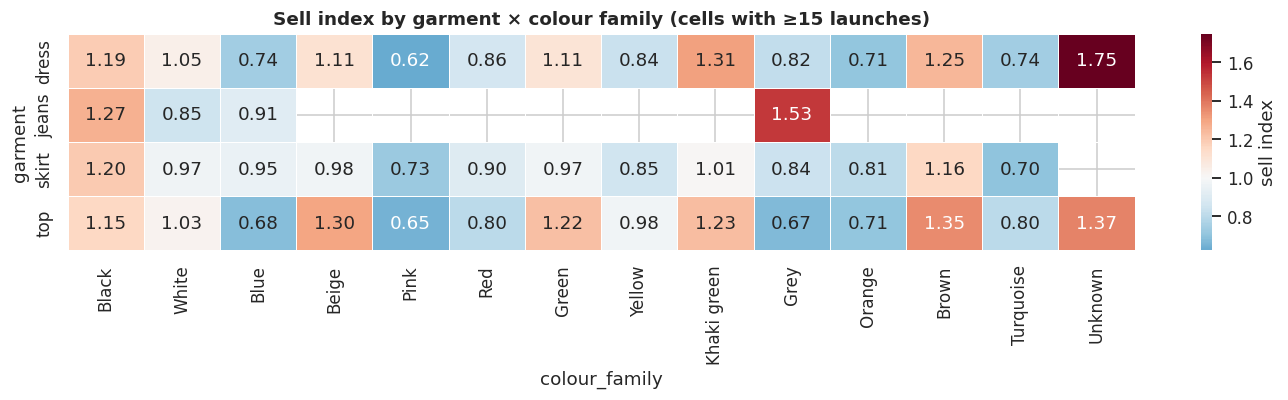

**What it shows:** Which colours sold best for each garment: each cell is the average 12-week sales of products in that colour, relative to the garment's average (1.00 = average).  
**How we made it:** Grouped H&M's real launches by garment and colour family and averaged their sell index; cells with fewer than 15 products are left blank.

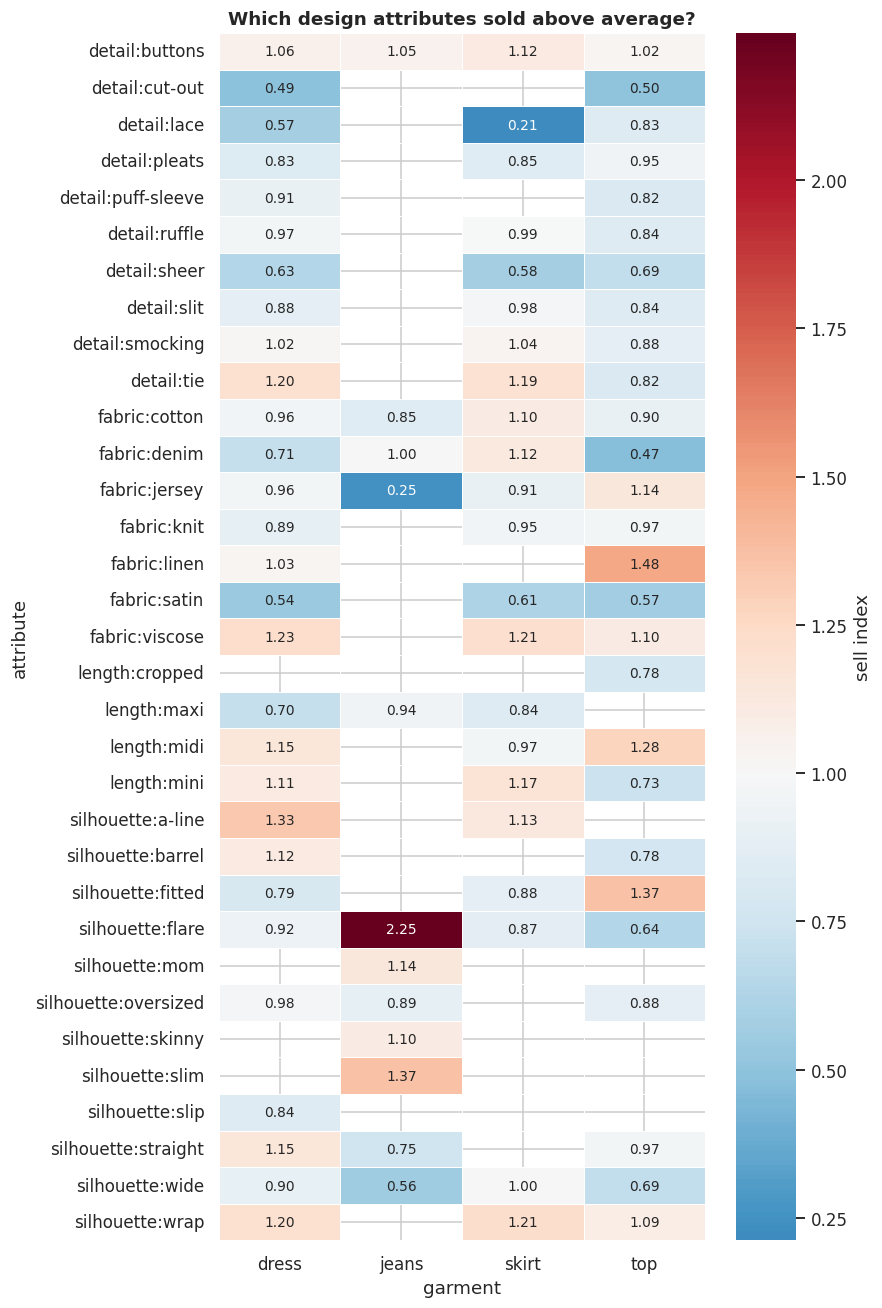

**What it shows:** Which design details, cuts, lengths and fabrics sold above or below average for each garment (red = above, blue = below).  
**How we made it:** Detected each attribute in H&M's product names and descriptions with text rules, then averaged the sell index of the products that have it.

In [32]:
def sell_heatmap(row: str, col: str, min_n: int = 15, title: str = "", ax=None, top_cols: int | None = None):
    g = products.groupby([row, col])["sell_index"].agg(["mean", "size"]).reset_index()
    g = g[g["size"] >= min_n]
    pivot = g.pivot(index=row, columns=col, values="mean")
    if top_cols:
        keep = products[col].value_counts().index[:top_cols]
        pivot = pivot[[c for c in keep if c in pivot.columns]]
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, linewidths=0.5, ax=ax,
                cbar_kws={"label": "sell index"})
    (ax or plt.gca()).set_title(title)
    return pivot


fig, ax = plt.subplots(figsize=(13, 3.8))
sell_heatmap("garment", "colour_family", title="Sell index by garment × colour family (cells with ≥15 launches)",
             ax=ax, top_cols=14)
show_fig("Which colours sold best for each garment: each cell is the average 12-week sales of products in that colour, relative to the garment's average (1.00 = average).",
         "Grouped H&M's real launches by garment and colour family and averaged their sell index; cells with fewer than 15 products are left blank.")

# Detail × garment
rows = []
for key in [k for k in ATTRS if k.startswith(("detail:", "silhouette:", "length:", "fabric:"))]:
    for g, grp in products[products[key] == 1].groupby("garment"):
        if len(grp) >= 15:
            rows.append({"attribute": key, "garment": g, "sell_index": grp["sell_index"].mean(), "n": len(grp)})
attr_perf = pd.DataFrame(rows)
attr_pivot = attr_perf.pivot(index="attribute", columns="garment", values="sell_index")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(attr_pivot) + 1.5))
sns.heatmap(attr_pivot, annot=True, fmt=".2f", annot_kws={"size": 9},
            cmap="RdBu_r", center=1.0, linewidths=0.5, ax=ax, cbar_kws={"label": "sell index"})
ax.set_title("Which design attributes sold above average?")
show_fig('Which design details, cuts, lengths and fabrics sold above or below average for each garment (red = above, blue = below).',
         "Detected each attribute in H&M's product names and descriptions with text rules, then averaged the sell index of the products that have it.")

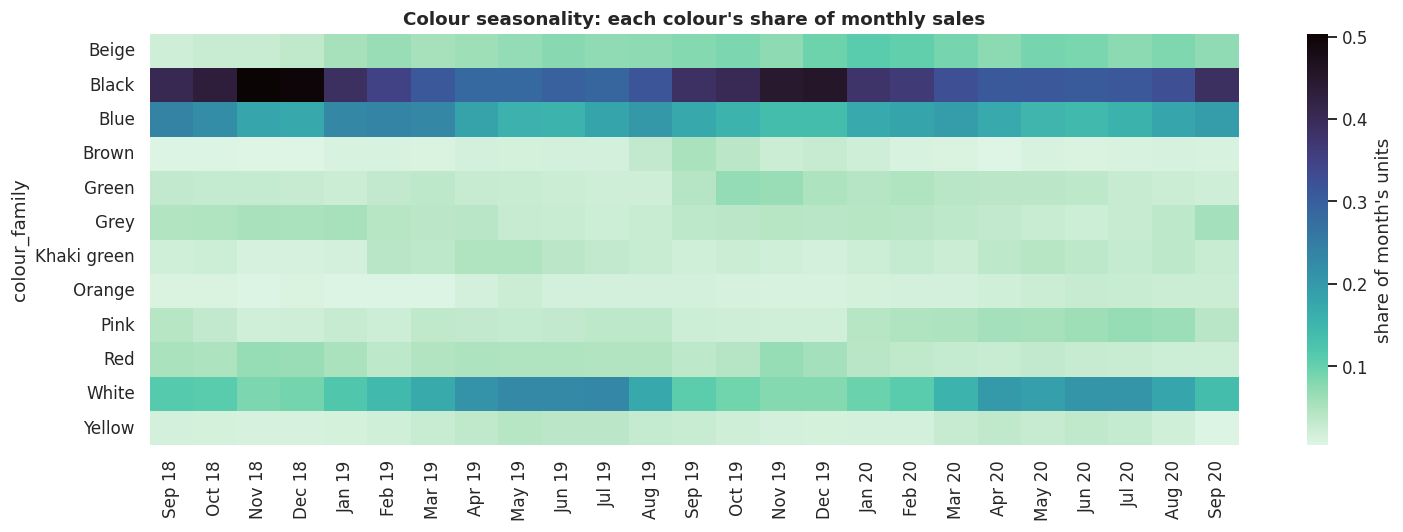

**What it shows:** How each colour's share of H&M's sales rises and falls through the year.  
**How we made it:** Summed weekly units by colour family and month from the 31M transactions, then divided by each month's total.

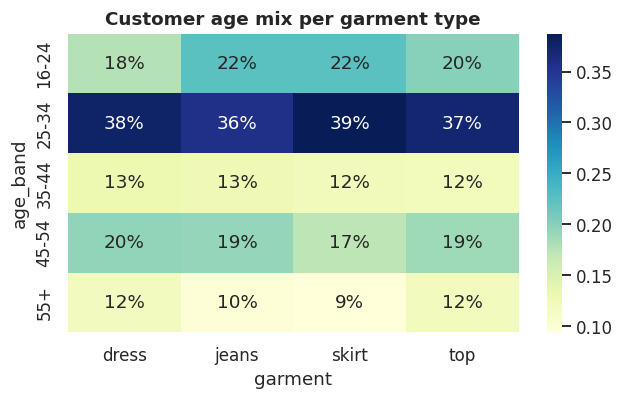

**What it shows:** Which age groups buy each garment type.  
**How we made it:** Joined every purchase to the buyer's age from H&M's customer file and computed each age band's share of units.

In [33]:
# Seasonality: weekly units by colour family over time (share of the week's sales, so growth in the panel doesn't dominate)
wk = weekly_units.merge(articles[["article_id", "colour_family", "garment"]], on="article_id")
wk["month"] = wk["week"].dt.to_period("M").dt.to_timestamp()
top_colours = wk.groupby("colour_family")["units"].sum().nlargest(12).index
share = (wk[wk["colour_family"].isin(top_colours)].groupby(["month", "colour_family"])["units"].sum()
         .groupby(level=0).transform(lambda s: s / s.sum()).unstack().T)
share.columns = [c.strftime("%b %y") for c in share.columns]
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(share, cmap="mako_r", ax=ax, cbar_kws={"label": "share of month's units"})
ax.set_title("Colour seasonality: each colour's share of monthly sales")
show_fig("How each colour's share of H&M's sales rises and falls through the year.",
         "Summed weekly units by colour family and month from the 31M transactions, then divided by each month's total.")

# Who buys what: age band × garment
ages_g = age_units.merge(articles[["article_id", "garment"]], on="article_id")
ages_g = ages_g[ages_g["age_band"].isin(AGE_BANDS)]
age_share = ages_g.pivot_table(index="age_band", columns="garment", values="units", aggfunc="sum")
age_share = (age_share / age_share.sum()).reindex(AGE_BANDS)
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(age_share, annot=True, fmt=".0%", cmap="YlGnBu", ax=ax)
ax.set_title("Customer age mix per garment type")
show_fig('Which age groups buy each garment type.',
         "Joined every purchase to the buyer's age from H&M's customer file and computed each age band's share of units.")

## 6. Trend sources: Google Trends and Pantone
### 6a. Google Trends
Each keyword links to a design attribute the engine can recommend. Monthly worldwide interest is downloaded from Jan 2018 to today in **one request per keyword**, so the same scale covers both the H&M training period (2018–20) and today. Each series is divided by its own long-run average (1.0 = a normal month for that keyword), so keywords with very different search volumes become comparable.

If Google rate-limits the download (HTTP 429), wait a few minutes and rerun this cell: keywords already fetched are cached in Drive.

Platform-wide spikes removed (most keywords jumped together): Feb 2026, Mar 2026, Apr 2026, May 2026, Jun 2026, Sep 2026
Google Trends: 26 keywords, Jan 2018 → Oct 2026


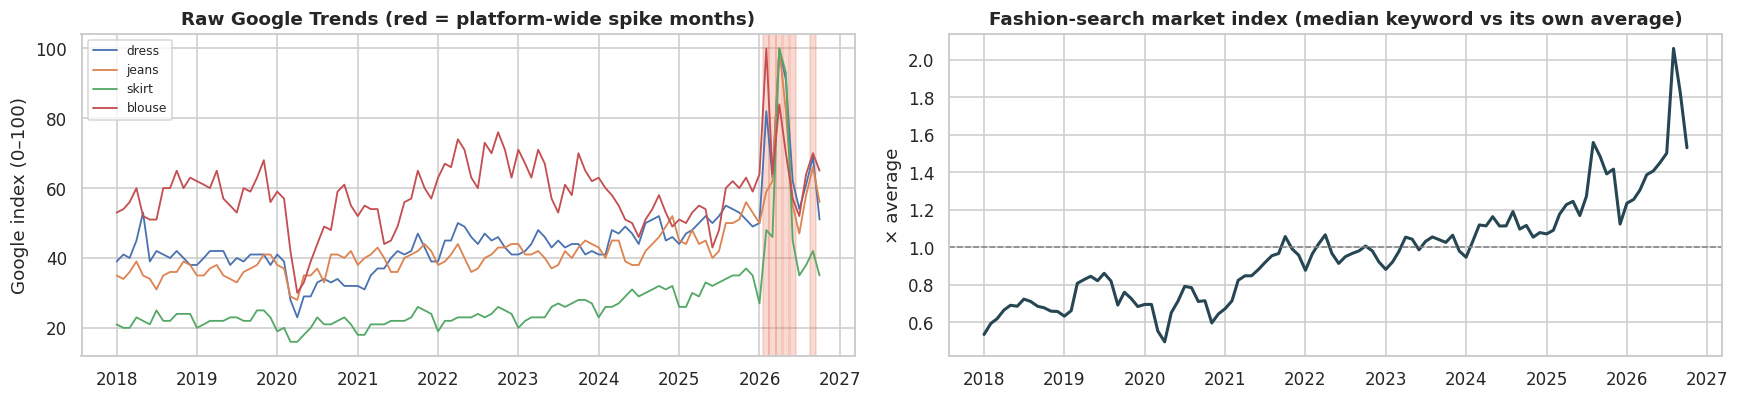

**What it shows:** Left: raw Google search interest for the four garment keywords, with months where almost every keyword jumped at once shaded red. Right: the overall level of fashion search over time.  
**How we made it:** Flagged months where at least 60% of keywords rose over 40% above both their previous 12-month median and the same month last year, and replaced them by interpolation; the market index is the median keyword's interest relative to its own average.

In [34]:
TREND_KEYWORDS = {
    # keyword: (garment or None for any, linked attribute or None for the garment baseline)
    "dress": ("dress", None), "jeans": ("jeans", None), "skirt": ("skirt", None), "blouse": ("top", None),
    "wide leg jeans": ("jeans", "silhouette:wide"), "skinny jeans": ("jeans", "silhouette:skinny"),
    "mom jeans": ("jeans", "silhouette:mom"), "straight leg jeans": ("jeans", "silhouette:straight"),
    "barrel jeans": ("jeans", "silhouette:barrel"), "flare jeans": ("jeans", "silhouette:flare"),
    "slip dress": ("dress", "silhouette:slip"), "wrap dress": ("dress", "silhouette:wrap"),
    "maxi dress": ("dress", "length:maxi"), "midi skirt": ("skirt", "length:midi"),
    "mini skirt": ("skirt", "length:mini"), "pleated skirt": ("skirt", "detail:pleats"),
    "satin skirt": ("skirt", "fabric:satin"), "denim skirt": ("skirt", "fabric:denim"),
    "puff sleeve": (None, "detail:puff-sleeve"), "lace top": ("top", "detail:lace"),
    "corset top": ("top", "detail:corset"), "linen dress": (None, "fabric:linen"),
    "polka dot dress": (None, "pattern:dot"), "cut out dress": (None, "detail:cut-out"),
    "smocked dress": (None, "detail:smocking"), "ruffle blouse": (None, "detail:ruffle"),
}
GT_CACHE = CACHE_DIR / "google_trends_monthly.csv"


def fetch_google_trends(keywords: list[str], cached: pd.DataFrame | None) -> pd.DataFrame:
    from pytrends.request import TrendReq
    py = TrendReq(hl="en-US", tz=0, timeout=(10, 30))
    timeframe = f"2018-01-01 {AS_OF.isoformat()}"
    out = cached.copy() if cached is not None else pd.DataFrame()
    for kw in keywords:
        for attempt in range(4):
            try:
                py.build_payload([kw], timeframe=timeframe, geo="")
                s = py.interest_over_time()[kw].astype(float)
                out[kw] = s
                print(f"  ✓ {kw}")
                break
            except Exception as exc:  # 429 / network
                wait = 20 * (attempt + 1)
                print(f"  … {kw}: {type(exc).__name__}, retrying in {wait}s")
                time.sleep(wait)
        else:
            print(f"  ✗ {kw}: skipped after 4 attempts (rerun later)")
        out.index.name = "month"
        out.to_csv(GT_CACHE)  # save progress after every keyword
        time.sleep(4)
    return out


cached = pd.read_csv(GT_CACHE, index_col="month", parse_dates=True) if GT_CACHE.exists() else None
todo = list(TREND_KEYWORDS) if (cached is None or REFRESH_TRENDS) else [k for k in TREND_KEYWORDS if k not in cached.columns]
if todo:
    try:
        print(f"Downloading Google Trends for {len(todo)} keywords …")
        gt = fetch_google_trends(todo, None if REFRESH_TRENDS else cached)
    except ImportError:
        if cached is None:
            raise RuntimeError("pytrends is not installed and there is no cached Google Trends file.")
        print("pytrends unavailable — using the cached Google Trends file.")
        gt = cached
else:
    gt = cached
gt = gt.sort_index()
gt.index = pd.to_datetime(gt.index).to_period("M").to_timestamp()
gt = gt[[k for k in TREND_KEYWORDS if k in gt.columns]]
if gt.index.max() >= pd.Timestamp(AS_OF.replace(day=1)):
    gt = gt.iloc[:-1]  # drop the current, incomplete month
gt_raw = gt.copy()


def clean_platform_spikes(df: pd.DataFrame, jump: float = 1.4, share: float = 0.6) -> tuple[pd.DataFrame, pd.Series]:
    """Flag months where most keywords jump together far above their own previous 12 months.
    A real fashion trend moves a few keywords; a jump in almost all of them at once is a change on
    Google's side (data collection or a spike in automated traffic), so those months are replaced by
    interpolation instead of being read as a trend."""
    clean = df.astype(float).copy()
    flagged = pd.Series(False, index=df.index)
    for i in range(12, len(df)):
        # Baseline = the higher of the previous 12 months' median and the same month last year,
        # so a normal seasonal peak (dresses in summer) is never mistaken for a spike
        base = np.maximum(clean.iloc[i - 12:i].median(), clean.iloc[i - 12].fillna(0))
        ratio = df.iloc[i] / base.replace(0, np.nan)
        if (ratio > jump).mean() >= share:
            flagged.iloc[i] = True
            clean.iloc[i] = np.nan
    clean = np.exp(np.log(clean.clip(lower=0.5)).interpolate(limit_direction="both"))
    return clean, flagged


gt, spike_months = clean_platform_spikes(gt_raw)
if spike_months.any():
    print("Platform-wide spikes removed (most keywords jumped together):",
          ", ".join(d.strftime("%b %Y") for d in spike_months[spike_months].index))
gt_rel = gt / gt.mean().replace(0, np.nan)   # 1.0 = a normal month for that keyword
gt_rel = gt_rel.fillna(0.0)
# Fashion-search market index: the typical keyword's level each month. Dividing by it turns each keyword
# into its share of fashion search, so a change that lifts every keyword (more Google users, a change in how
# Google counts searches) doesn't look like every trend rising or fading at once.
market = gt_rel.median(axis=1)
gt_share = gt_rel.div(market.replace(0, np.nan), axis=0).fillna(1.0)
print(f"Google Trends: {gt.shape[1]} keywords, {gt.index.min():%b %Y} → {gt.index.max():%b %Y}")

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for kw in ["dress", "jeans", "skirt", "blouse"]:
    if kw in gt_raw:
        axes[0].plot(gt_raw.index, gt_raw[kw], lw=1.2, label=kw)
for d in spike_months[spike_months].index:
    axes[0].axvspan(d - pd.Timedelta(days=14), d + pd.Timedelta(days=14), color="#e76f51", alpha=0.25)
axes[0].set(title="Raw Google Trends (red = platform-wide spike months)", ylabel="Google index (0–100)")
axes[0].legend(fontsize=8)
axes[1].plot(market.index, market, color="#264653", lw=2)
axes[1].axhline(1, color="grey", ls="--", lw=1)
axes[1].set(title="Fashion-search market index (median keyword vs its own average)", ylabel="× average")
show_fig("Left: raw Google search interest for the four garment keywords, with months where almost every keyword jumped at "
         "once shaded red. Right: the overall level of fashion search over time.",
         "Flagged months where at least 60% of keywords rose over 40% above both their previous 12-month median and the same month last year, and replaced them by "
         "interpolation; the market index is the median keyword's interest relative to its own average.")

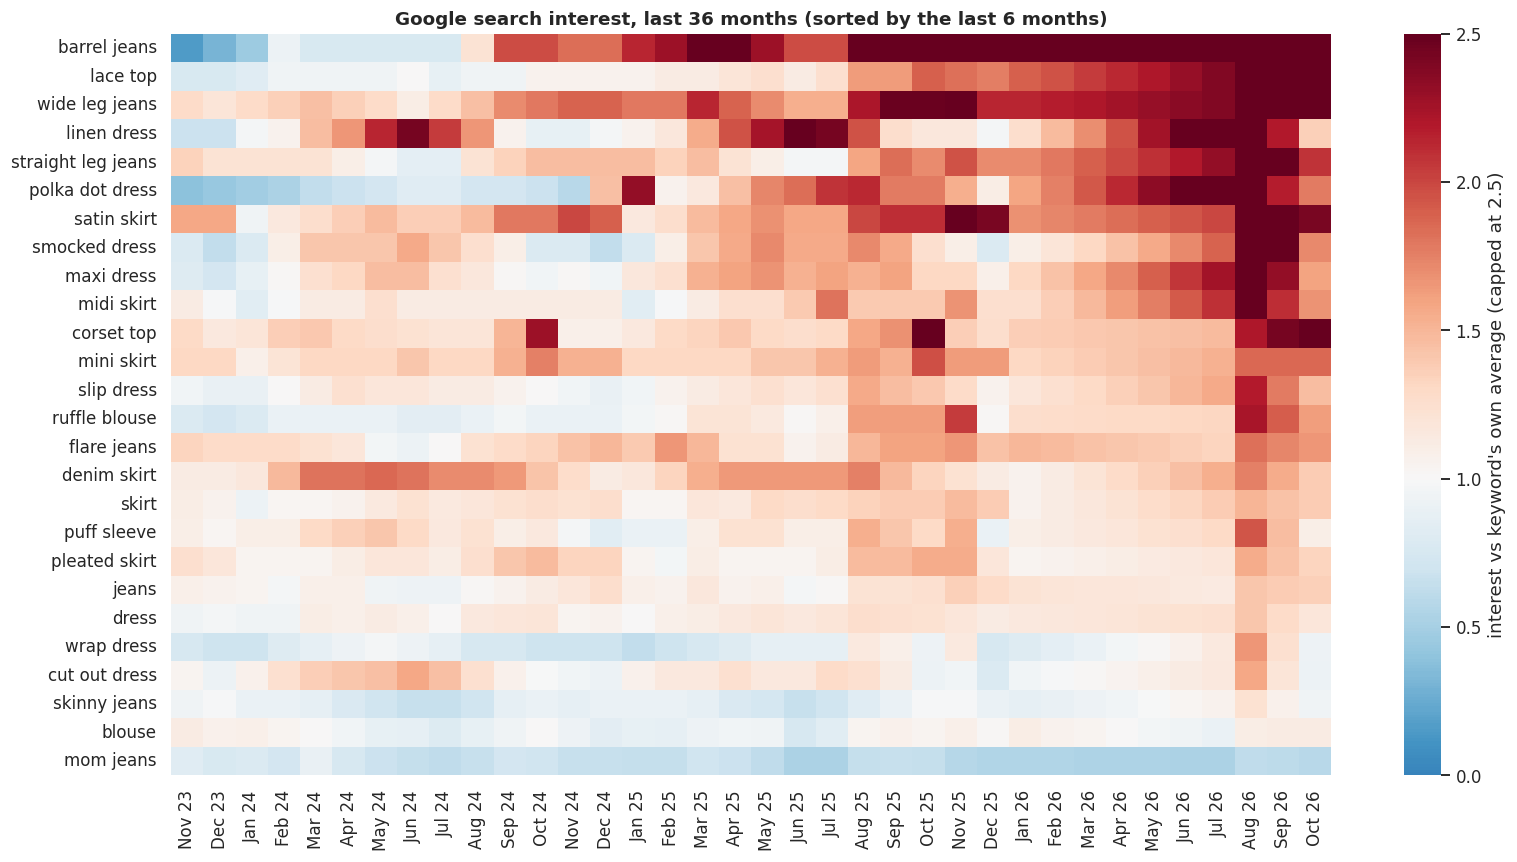

**What it shows:** How much people are searching for each fashion keyword now compared with normal (red = above normal).  
**How we made it:** Downloaded monthly worldwide Google Trends data for each keyword and divided it by that keyword's long-run average, so all keywords share one scale.

In [35]:
recent = gt_rel.loc[gt_rel.index >= gt_rel.index.max() - pd.DateOffset(months=35)].T
recent.columns = [c.strftime("%b %y") for c in recent.columns]
recent = recent.loc[recent.iloc[:, -6:].mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 8))
sns.heatmap(recent, cmap="RdBu_r", center=1.0, vmin=0, vmax=2.5, ax=ax,
            cbar_kws={"label": "interest vs keyword's own average (capped at 2.5)"})
ax.set_title("Google search interest, last 36 months (sorted by the last 6 months)")
show_fig('How much people are searching for each fashion keyword now compared with normal (red = above normal).',
         "Downloaded monthly worldwide Google Trends data for each keyword and divided it by that keyword's long-run average, so all keywords share one scale.")

### 6b. Trend momentum, status and projection to launch
Search interest is strongly seasonal (dresses peak in summer), so momentum is measured **year on year**, where the season cancels out, and **relative to the fashion-search market**, so only keywords that gain or lose share of fashion search count as trends.

- **Momentum** = the keyword's share of fashion search in the last 3 months vs the same 3 months a year earlier.
- **Status**: *rising* (share up more than 10% and still accelerating or steady), *peaking* (share up but slowing sharply, or within ±10%), *fading* (share down more than 10%).
- **Projection to launch**: the same months last year × the keyword's year-on-year growth, damped by half (fashion momentum rarely continues at full speed). This keeps each keyword's own seasonality.
- The deseasonalised curve (seasonal profile removed, 3-month smoothing) is kept for the lifecycle clustering in 6c.

,keyword,garment,attribute,yoy_change_pct,raw_search_yoy_pct,momentum_3m_earlier_pct,status,now,at_launch
0,lace top,top,detail:lace,52.2,86.2,59.8,rising,3.20,2.42
1,smocked dress,any,detail:smocking,52.2,90.5,-10.2,rising,2.89,1.48
2,maxi dress,dress,length:maxi,31.4,63.6,8.9,rising,2.43,1.65
3,barrel jeans,jeans,silhouette:barrel,29.7,55.1,51.5,rising,6.61,4.59
4,linen dress,any,fabric:linen,28.9,61.0,-9.2,rising,2.36,1.68
5,midi skirt,skirt,length:midi,24.6,53.7,9.5,rising,2.14,1.53
6,straight leg jeans,jeans,silhouette:straight,23.7,52.4,83.1,peaking,2.60,2.00
7,satin skirt,skirt,fabric:satin,6.3,29.5,1.7,peaking,2.68,1.79
8,corset top,top,detail:corset,5.3,26.9,-4.4,peaking,2.43,1.42
9,wide leg jeans,jeans,silhouette:wide,0.8,23.0,24.4,peaking,2.94,2.18


**What it shows:** Each tracked keyword's momentum: its change in share of fashion search year on year (yoy_change_pct), the raw change in searches, the momentum three months earlier, its status, and projected interest at launch (1.00 = a normal month).  
**How we made it:** Compared the last 3 months with the same months a year earlier, after dividing by the fashion-search market index; status is rising, peaking or fading from that change and whether it is speeding up or slowing down.

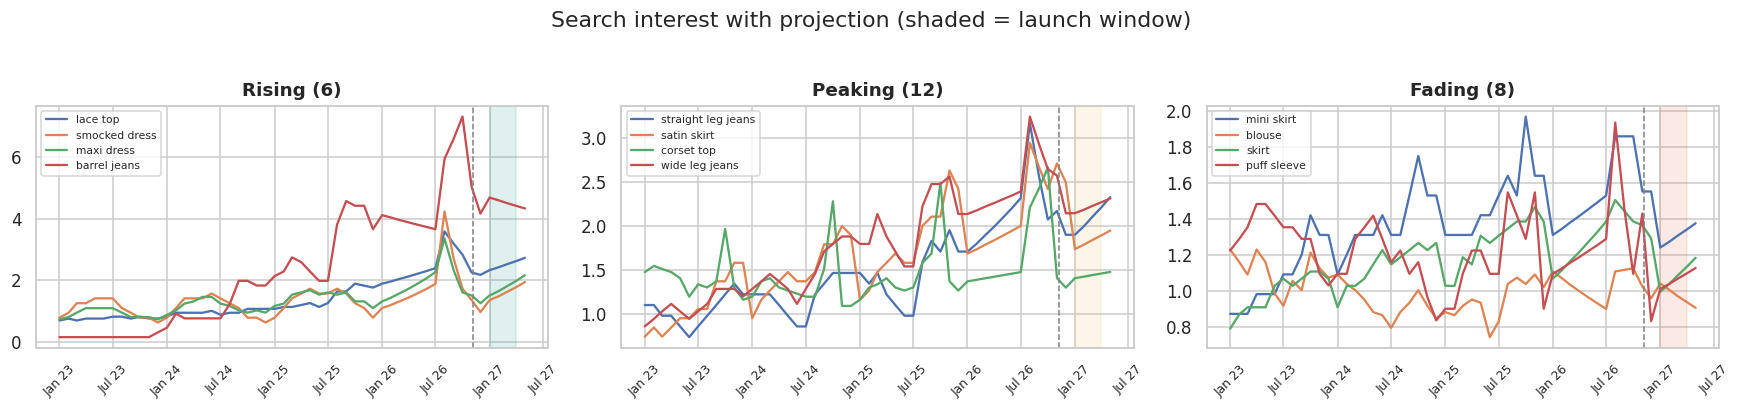

**What it shows:** Which trends are rising, peaking or fading, and where each is projected to be when the designs launch (shaded band).  
**How we made it:** Projected each keyword from the same months last year multiplied by its year-on-year growth in share of fashion search, damped by half.

In [36]:
def seasonal_profile(s: pd.Series) -> pd.Series:
    prof = s.groupby(s.index.month).median()
    return (prof / prof.mean()).replace(0, np.nan).fillna(1.0)


def deseasonalise(s: pd.Series) -> pd.Series:
    return (s / s.index.month.map(seasonal_profile(s)).to_numpy()).ewm(span=3, adjust=False).mean()


def yoy(s: pd.Series, end: int) -> float:
    """% change of the 3 months ending `end` months before the last vs the same months a year earlier."""
    recent = s.iloc[len(s) - 3 - end:len(s) - end].mean()
    year_ago = s.iloc[len(s) - 15 - end:len(s) - 12 - end].mean()
    return float((recent / year_ago - 1) * 100) if year_ago > 0.05 else (100.0 if recent > 0.05 else 0.0)


def project(s: pd.Series, months_ahead: int, growth: float) -> pd.Series:
    """Seasonal-naive projection: same month last year × damped year-on-year growth."""
    future_idx = pd.date_range(s.index[-1] + pd.offsets.MonthBegin(1), periods=months_ahead, freq="MS")
    damped = float(np.clip(growth, 0.25, 4.0)) ** 0.5
    ext = s.copy()
    for d in future_idx:
        ext.loc[d] = ext.get(d - pd.DateOffset(years=1), s.iloc[-12:].mean()) * (damped if d - pd.DateOffset(years=1) <= s.index[-1] else 1.0)
    return ext.loc[future_idx]


launch_month = pd.Timestamp(LAUNCH_WEEK.replace(day=1))
months_ahead = (launch_month.year - gt_rel.index[-1].year) * 12 + launch_month.month - gt_rel.index[-1].month + 4
trend_rows, projections, deseasonalised = [], {}, {}
for kw, (garment, attr) in TREND_KEYWORDS.items():
    if kw not in gt_rel:
        continue
    s, share_s = gt_rel[kw], gt_share[kw]
    raw_yoy, share_yoy, share_yoy_before = yoy(s, 0), yoy(share_s, 0), yoy(share_s, 3)
    if share_yoy > 10 and share_yoy >= share_yoy_before - 25:
        status = "rising"
    elif share_yoy < -10:
        status = "fading"
    else:
        status = "peaking"
    growth = 1 + share_yoy / 100   # the keyword's own trend growth, not the market's
    proj = project(s, months_ahead, growth)
    projections[kw] = pd.concat([s, proj])
    deseasonalised[kw] = deseasonalise(share_s)
    at_launch = float(projections[kw].loc[launch_month:].iloc[:3].mean())
    trend_rows.append({"keyword": kw, "garment": garment or "any", "attribute": attr or f"{garment} (baseline)",
                       "yoy_change_pct": round(share_yoy, 1), "raw_search_yoy_pct": round(raw_yoy, 1),
                       "momentum_3m_earlier_pct": round(share_yoy_before, 1), "status": status,
                       "now": round(float(s.iloc[-3:].mean()), 2), "at_launch": round(at_launch, 2)})
trend_table = pd.DataFrame(trend_rows).sort_values("yoy_change_pct", ascending=False).reset_index(drop=True)
display(trend_table)
note("Each tracked keyword's momentum: its change in share of fashion search year on year (yoy_change_pct), the raw change "
     "in searches, the momentum three months earlier, its status, and projected interest at launch (1.00 = a normal month).",
     "Compared the last 3 months with the same months a year earlier, after dividing by the fashion-search market index; "
     "status is rising, peaking or fading from that change and whether it is speeding up or slowing down.")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=False)
for ax, (status, colour) in zip(axes, [("rising", "#2a9d8f"), ("peaking", "#e9c46a"), ("fading", "#e76f51")]):
    kws = trend_table[trend_table["status"] == status]["keyword"].head(4)
    for kw in kws:
        series = projections[kw].loc["2023":]
        ax.plot(series.index, series.values, label=kw)
    ax.axvline(pd.Timestamp(AS_OF), color="grey", ls="--", lw=1)
    ax.axvspan(launch_month, launch_month + pd.DateOffset(months=3), color=colour, alpha=0.15)
    ax.set_title(f"{status.title()} ({(trend_table['status'] == status).sum()})")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.legend(fontsize=7)
fig.suptitle("Search interest with projection (shaded = launch window)", y=1.03)
show_fig('Which trends are rising, peaking or fading, and where each is projected to be when the designs launch (shaded band).',
         "Projected each keyword from the same months last year multiplied by its year-on-year growth in share of fashion search, damped by half.")

### 6c. Trend lifecycle clustering (unsupervised ML)
Do the keywords fall into natural lifecycle groups? Each keyword's deseasonalised curve over the last 36 months is z-normalised and clustered with **k-means**; the number of clusters is chosen by the **silhouette score**.

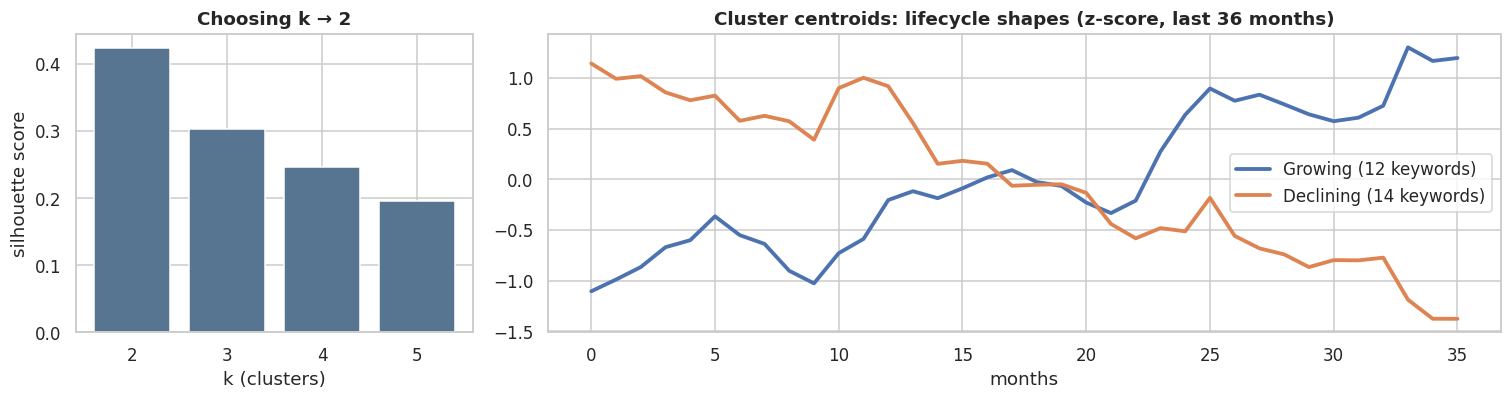

**What it shows:** The typical lifecycle shapes the trends fall into, such as growing or declining.  
**How we made it:** Clustered the keywords' deseasonalised 36-month curves with k-means, choosing the number of clusters by silhouette score.

,keyword
lifecycle,
Declining,"corset top, skinny jeans, wrap dress, jeans, f..."
Growing,"lace top, smocked dress, maxi dress, barrel je..."


In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

curves = pd.DataFrame({k: v.iloc[-36:].to_numpy() for k, v in deseasonalised.items()}).T
curves_z = curves.sub(curves.mean(axis=1), axis=0).div(curves.std(axis=1).replace(0, 1), axis=0)
sil = {}
for k in range(2, min(6, len(curves_z) - 1)):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_SEED).fit(curves_z)
    sil[k] = silhouette_score(curves_z, km.labels_)
best_k = max(sil, key=sil.get)
km = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_SEED).fit(curves_z)
centroid_slope = {c: np.polyfit(np.arange(12), km.cluster_centers_[c][-12:], 1)[0] for c in range(best_k)}
order = sorted(centroid_slope, key=centroid_slope.get, reverse=True)
names = ["Emerging", "Building", "Stable", "Cooling", "Declining"]
label_names = {c: names[i] if best_k > 2 else ["Growing", "Declining"][i] for i, c in enumerate(order)}
lifecycle = pd.Series({kw: label_names[c] for kw, c in zip(curves_z.index, km.labels_)}, name="lifecycle")
trend_table = trend_table.merge(lifecycle, left_on="keyword", right_index=True, how="left")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].bar(list(sil), list(sil.values()), color="#577590")
axes[0].set(xlabel="k (clusters)", ylabel="silhouette score", title=f"Choosing k → {best_k}")
for c in order:
    axes[1].plot(km.cluster_centers_[c], lw=2.5, label=f"{label_names[c]} ({(km.labels_ == c).sum()} keywords)")
axes[1].set(title="Cluster centroids: lifecycle shapes (z-score, last 36 months)", xlabel="months")
axes[1].legend()
show_fig('The typical lifecycle shapes the trends fall into, such as growing or declining.',
         "Clustered the keywords' deseasonalised 36-month curves with k-means, choosing the number of clusters by silhouette score.")
display(trend_table.groupby("lifecycle")["keyword"].apply(", ".join).to_frame())

### 6d. Pantone colour trends
Pantone doesn't offer a public data feed, so its reports are entered here as a curated table, each colour mapped to the closest H&M colour group in the sales data. Sources: Pantone Colour of the Year 2026 (*Cloud Dancer*, announced Dec 2025) and Pantone's NYFW colour trend reports for **Autumn/Winter 2026** (Feb 2026) and **Spring/Summer 2027** (Sep 2026). The briefs launch in spring 2027, so the SS27 report carries the most weight. Hex values are approximate screen colours for display only.

*Update this table each season when Pantone publishes a new report.*

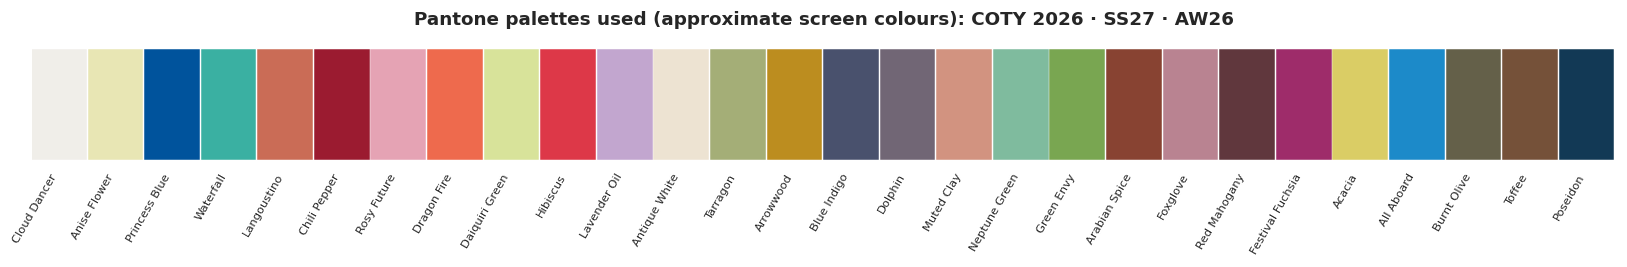

**What it shows:** The Pantone colours used as colour-trend signals.  
**How we made it:** Entered Pantone's Colour of the Year 2026 and NYFW AW26 and SS27 palettes by hand and matched each colour to the closest H&M colour group.

,pantone_name,tcx,palette,hm_colour,hm_sell_index,hm_launches
0,Cloud Dancer,11-4201,Colour of the Year 2026,Off White,1.02,507
1,Anise Flower,12-0717,SS27 NYFW,Light Yellow,0.71,142
2,Princess Blue,19-4150,SS27 NYFW,Blue,0.83,453
3,Waterfall,15-5516,SS27 NYFW,Turquoise,0.74,48
4,Langoustino,16-1440,SS27 NYFW,Dark Orange,1.27,199
5,Chili Pepper,19-1557,SS27 NYFW,Dark Red,0.88,215
6,Rosy Future,15-1910,SS27 NYFW,Pink,0.65,236
7,Dragon Fire,16-1460,SS27 NYFW,Orange,0.66,93
8,Daiquiri Green,12-0435,SS27 NYFW,Light Green,0.80,104
9,Hibiscus,18-1762,SS27 NYFW,Red,0.85,380


**What it shows:** Each Pantone trend colour, the H&M colour group it maps to, and how that colour group sold at H&M.  
**How we made it:** Matched each Pantone colour to the closest H&M colour group by hand, then averaged the sell index of H&M launches in that group.

In [38]:
PANTONE = [
    # name, TCX code, approx hex, H&M colour group, palette, weight
    ("Cloud Dancer", "11-4201", "#F0EEE9", "Off White", "Colour of the Year 2026", 0.9),
    ("Anise Flower", "12-0717", "#E8E6B4", "Light Yellow", "SS27 NYFW", 1.0),
    ("Princess Blue", "19-4150", "#00539C", "Blue", "SS27 NYFW", 1.0),
    ("Waterfall", "15-5516", "#3AB0A2", "Turquoise", "SS27 NYFW", 1.0),
    ("Langoustino", "16-1440", "#CA6C56", "Dark Orange", "SS27 NYFW", 1.0),
    ("Chili Pepper", "19-1557", "#9B1B30", "Dark Red", "SS27 NYFW", 1.0),
    ("Rosy Future", "15-1910", "#E5A3B4", "Pink", "SS27 NYFW", 1.0),
    ("Dragon Fire", "16-1460", "#EE6A4D", "Orange", "SS27 NYFW", 1.0),
    ("Daiquiri Green", "12-0435", "#D8E39A", "Light Green", "SS27 NYFW", 1.0),
    ("Hibiscus", "18-1762", "#DD3848", "Red", "SS27 NYFW", 1.0),
    ("Lavender Oil", "15-3615", "#C2A6CF", "Light Purple", "SS27 NYFW", 1.0),
    ("Antique White", "11-0105", "#EDE3D2", "Off White", "SS27 neutrals", 0.8),
    ("Tarragon", "15-0326", "#A4AE77", "Greenish Khaki", "SS27 neutrals", 0.8),
    ("Arrowwood", "16-0954", "#BC8D1F", "Dark Yellow", "SS27 neutrals", 0.8),
    ("Blue Indigo", "19-3928", "#49516D", "Dark Blue", "SS27 neutrals", 0.8),
    ("Dolphin", "16-2901", "#716675", "Grey", "SS27 neutrals", 0.8),
    ("Muted Clay", "16-1330", "#D29380", "Dark Beige", "AW26 NYFW", 0.5),
    ("Neptune Green", "14-6017", "#7FBB9E", "Light Turquoise", "AW26 NYFW", 0.5),
    ("Green Envy", "16-0541", "#79A651", "Green", "AW26 NYFW", 0.5),
    ("Arabian Spice", "19-1245", "#884332", "Yellowish Brown", "AW26 NYFW", 0.5),
    ("Foxglove", "16-1710", "#B98391", "Dark Pink", "AW26 NYFW", 0.5),
    ("Red Mahogany", "19-1521", "#60373D", "Dark Red", "AW26 NYFW", 0.5),
    ("Festival Fuchsia", "19-2434", "#9E2C6A", "Dark Pink", "AW26 NYFW", 0.5),
    ("Acacia", "13-0640", "#DACD65", "Yellow", "AW26 NYFW", 0.5),
    ("All Aboard", "17-4140", "#1C8AC9", "Blue", "AW26 NYFW", 0.5),
    ("Burnt Olive", "18-0521", "#646049", "Dark Green", "AW26 NYFW", 0.5),
    ("Toffee", "18-1031", "#755139", "Yellowish Brown", "AW26 neutrals", 0.4),
    ("Poseidon", "19-4033", "#123955", "Dark Blue", "AW26 neutrals", 0.4),
]
pantone = pd.DataFrame(PANTONE, columns=["pantone_name", "tcx", "hex", "hm_colour", "palette", "weight"])
pantone_score = pantone.groupby("hm_colour")["weight"].max()   # 0–1 per H&M colour group

colour_perf = products.groupby("colour")["sell_index"].agg(["mean", "size"])
colour_view = pantone.merge(colour_perf, left_on="hm_colour", right_index=True, how="left").rename(
    columns={"mean": "hm_sell_index", "size": "hm_launches"})
fig, ax = plt.subplots(figsize=(15, 2.6))
for i, r in pantone.iterrows():
    ax.add_patch(plt.Rectangle((i, 0), 0.95, 1, color=r["hex"]))
    ax.text(i + 0.47, -0.12, r["pantone_name"], rotation=60, ha="right", va="top", fontsize=7.5)
ax.set_xlim(0, len(pantone)); ax.set_ylim(-0.1, 1.15); ax.axis("off")
ax.set_title("Pantone palettes used (approximate screen colours): COTY 2026 · SS27 · AW26")
show_fig('The Pantone colours used as colour-trend signals.',
         "Entered Pantone's Colour of the Year 2026 and NYFW AW26 and SS27 palettes by hand and matched each colour to the closest H&M colour group.")
display(colour_view[["pantone_name", "tcx", "palette", "hm_colour", "hm_sell_index", "hm_launches"]].round(2))
note("Each Pantone trend colour, the H&M colour group it maps to, and how that colour group sold at H&M.",
     "Matched each Pantone colour to the closest H&M colour group by hand, then averaged the sell index of H&M launches in that group.")

## 7. Demand model: 12-week sales for a new product
### 7a. Features
One row per product: the target is its **total units in the first 12 weeks** (the selling window the stock decision is about). Everything the model sees is known **at launch time** (no leakage), and every feature can also be computed for a brand-new design:

| Group | Features |
|---|---|
| What it is | garment type, colour family, solid vs print, silhouette/length/detail/fabric flags, sustainable, convertible |
| Price | price ÷ the garment's median price (log) |
| Market interest | Google Trends for the garment (seasonal demand) and for the product's own trend keywords over its 12-week window, both relative to their long-run average |
| Timing | season of launch (sine/cosine of week of year), share of the window in lockdown (Mar–Jun 2020 store closures) |

Why products, not weeks: week-by-week sales of a single new product are mostly noise, so a weekly model scores poorly on R² even when its 12-week totals are useful. Modelling the total directly gives a cleaner signal. The week-by-week shape for planning comes from H&M's typical sales curve after launch (shown below).

Training matrix: 11,740 products × 61 features


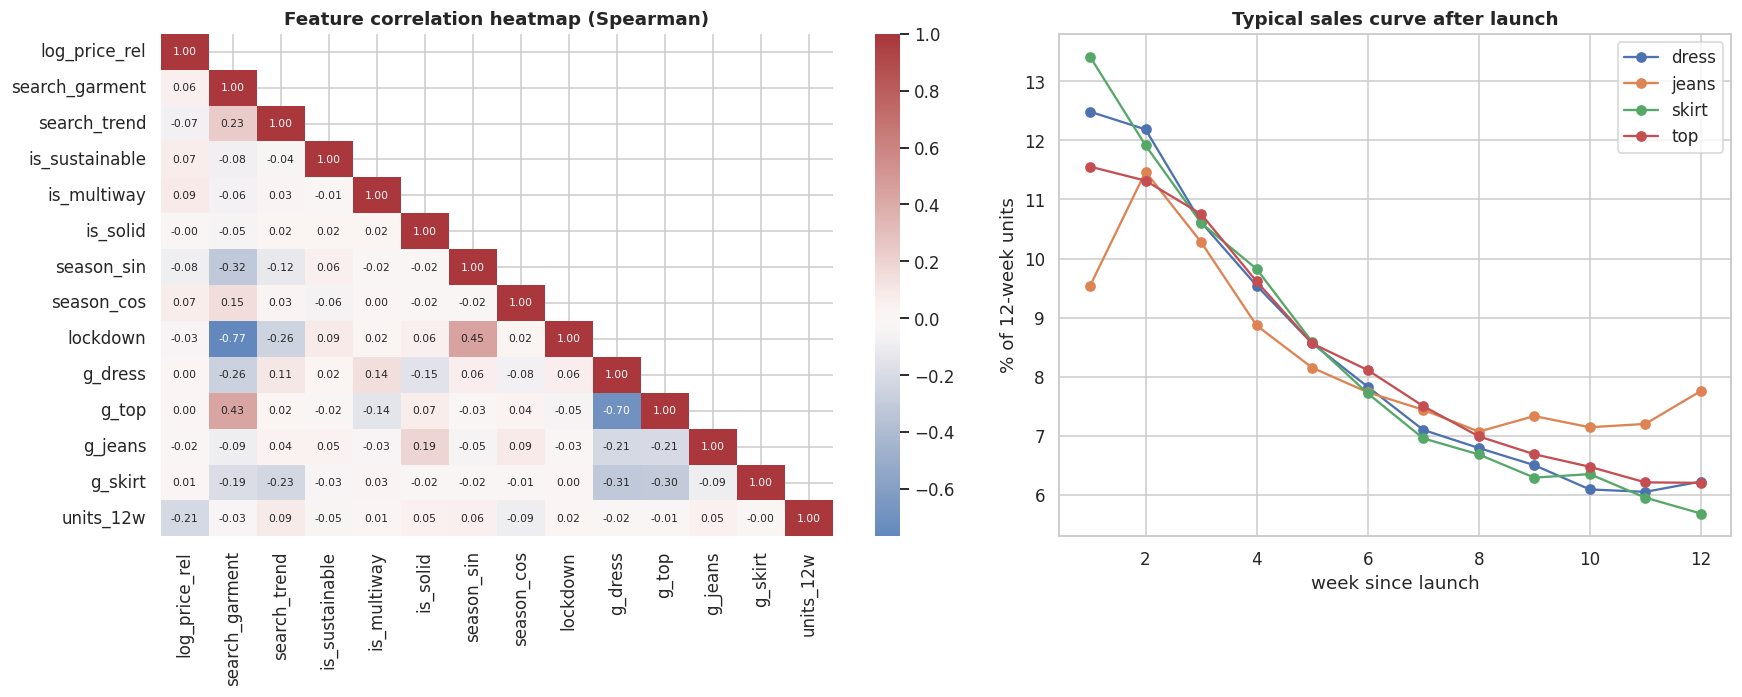

**What it shows:** Left: how the demand model's main inputs relate to each other and to 12-week sales. Right: how a new product's sales are spread across its first 12 weeks.  
**How we made it:** Left: Spearman rank correlations across all launches. Right: each product's weekly share of its 12-week units, averaged per garment.

In [39]:
COLOUR_FAMILIES = products["colour_family"].value_counts().index[:12].tolist()
LOCKDOWN = (pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-14"))
GARMENT_KW = {g: kw for kw, (g, a) in TREND_KEYWORDS.items() if a is None and kw in gt_rel}
ATTR_KWS = {}
for kw, (g, a) in TREND_KEYWORDS.items():
    if a is not None and kw in gt_rel:
        ATTR_KWS.setdefault(a, []).append((kw, g))
STATIC = ([f"g_{g}" for g in GARMENTS] + [f"col_{c}" for c in COLOUR_FAMILIES] + ["is_solid"] + ATTRS
          + ["is_sustainable", "is_multiway", "log_price_rel"])
LAUNCH_FEATS = ["search_garment", "search_trend", "has_trend_kw", "season_sin", "season_cos", "lockdown"]
FEATURES = STATIC + LAUNCH_FEATS


def matched_keywords(garment: str, attrs: dict) -> list[str]:
    return [kw for a, lst in ATTR_KWS.items() if attrs.get(a, 0) for kw, g in lst if g in (None, garment)]


def interest_at(series_map: dict, kws: list[str], month: pd.Timestamp) -> float:
    vals = [series_map[k].get(month, np.nan) for k in kws]
    vals = [v for v in vals if not pd.isna(v)]
    return float(np.mean(vals)) if vals else 1.0


def static_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    for g in GARMENTS:
        X[f"g_{g}"] = (df["garment"] == g).astype(float)
    for c in COLOUR_FAMILIES:
        X[f"col_{c}"] = (df["colour_family"] == c).astype(float)
    for col in ["is_solid", *ATTRS, "is_sustainable", "is_multiway"]:
        X[col] = df[col].astype(float)
    X["log_price_rel"] = np.log(df["price_rel"].clip(0.2, 5))
    return X


def time_features(weeks: pd.Series, garments: pd.Series, kw_lists: pd.Series, series_map: dict) -> pd.DataFrame:
    months = weeks.dt.to_period("M").dt.to_timestamp()
    woy = weeks.dt.isocalendar().week.astype(float).to_numpy()
    out = pd.DataFrame(index=weeks.index)
    out["search_garment"] = [series_map[GARMENT_KW[g]].get(m, 1.0) if g in GARMENT_KW else 1.0
                             for g, m in zip(garments, months)]
    out["search_trend"] = [interest_at(series_map, kws, m) for kws, m in zip(kw_lists, months)]
    out["has_trend_kw"] = [float(bool(k)) for k in kw_lists]
    out["season_sin"], out["season_cos"] = np.sin(2 * np.pi * woy / 52), np.cos(2 * np.pi * woy / 52)
    out["lockdown"] = ((weeks >= LOCKDOWN[0]) & (weeks <= LOCKDOWN[1])).astype(float)
    return out


def launch_features(rows: pd.DataFrame, launch_week, series_map: dict) -> pd.DataFrame:
    """Market interest averaged over the 12-week window; season taken at launch."""
    acc = None
    for h in range(SELL_WEEKS):
        wk_ = pd.Series([pd.Timestamp(launch_week) + pd.Timedelta(weeks=h)] * len(rows), index=rows.index) \
            if not isinstance(launch_week, pd.Series) else launch_week + pd.Timedelta(weeks=h)
        tf_ = time_features(wk_, rows["garment"], rows["trend_kws"], series_map)
        if h == 0:
            first = tf_
            acc = tf_[["search_garment", "search_trend", "lockdown"]].copy()
        else:
            acc += tf_[["search_garment", "search_trend", "lockdown"]]
    out = acc / SELL_WEEKS
    out["has_trend_kw"] = first["has_trend_kw"]
    out["season_sin"], out["season_cos"] = first["season_sin"], first["season_cos"]
    return out[LAUNCH_FEATS]


hist_series = {k: gt_rel[k].to_dict() for k in gt_rel.columns}
products["trend_kws"] = [matched_keywords(r["garment"], r) for _, r in products[["garment", *ATTRS]].iterrows()]
products = products.reset_index(drop=True)
static_X = static_features(products.set_index("article_id"))
Xp = pd.concat([static_X.reset_index(drop=True),
                launch_features(products, products["launch_week"], hist_series).reset_index(drop=True)], axis=1)[FEATURES]
yp = np.log1p(products["units_12w"].to_numpy())
launch_ord = products["launch_week"].map(pd.Timestamp.toordinal).to_numpy()
print(f"Training matrix: {Xp.shape[0]:,} products × {Xp.shape[1]} features")

# H&M's typical sales curve after launch (share of 12-week units sold in each week), per garment
WEEK_PROFILE = (panel.merge(products[["article_id", "garment", "units_12w"]], on="article_id")
                .query("units_12w > 0")
                .assign(share=lambda d: d["units"] / d["units_12w"])
                .groupby(["garment", "weeks_since_launch"])["share"].mean().unstack())
WEEK_PROFILE = WEEK_PROFILE.div(WEEK_PROFILE.sum(axis=1), axis=0)

corr_cols = ["log_price_rel", "search_garment", "search_trend", "is_sustainable", "is_multiway", "is_solid",
             "season_sin", "season_cos", "lockdown", "g_dress", "g_top", "g_jeans", "g_skirt"]
corr = pd.concat([Xp[corr_cols], pd.Series(products["units_12w"].to_numpy(), name="units_12w")], axis=1).corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[0],
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
axes[0].set_title("Feature correlation heatmap (Spearman)")
for g in WEEK_PROFILE.index:
    axes[1].plot(WEEK_PROFILE.columns + 1, WEEK_PROFILE.loc[g] * 100, marker="o", label=g)
axes[1].set(title="Typical sales curve after launch", xlabel="week since launch", ylabel="% of 12-week units")
axes[1].legend()
show_fig("Left: how the demand model's main inputs relate to each other and to 12-week sales. Right: how a new product's sales are spread across its first 12 weeks.",
         "Left: Spearman rank correlations across all launches. Right: each product's weekly share of its 12-week units, averaged per garment.")

### 7b. Model comparison
The **most recent 20% of launches** are held out, so every model is scored on products it has never seen, launched after everything it trained on. Models predict `log(1 + units)`. Scores: **R² (log)** is how much of the variation in (log) sales the model explains, the standard way to score skewed sales data; **R² (units)**, **MAE** and **WAPE** (total absolute error ÷ total units; lower is better) are on real units. A 3-fold **time-series cross-validation** (each fold trains on earlier launches, tests on the next block) checks the result isn't a fluke of one split.

,R² (log),R² (units),MAE,WAPE,fit seconds,"CV R² (log, mean of 3 folds)"
model,,,,,,
Baseline (garment average),-0.052,-0.272,274.862,0.739,—,—
Ridge regression,0.119,-0.079,255.164,0.686,0.600,-0.187
Random forest,0.205,-0.081,247.887,0.666,35.900,0.060
Gradient boosting,0.142,-0.046,248.792,0.669,19.000,-0.044


**What it shows:** Accuracy of each demand model on launches it never saw (higher R², lower MAE and WAPE are better).  
**How we made it:** Trained on the oldest 80% of launches, tested on the newest 20%, and repeated over 3 time-ordered folds for the cross-validation column.

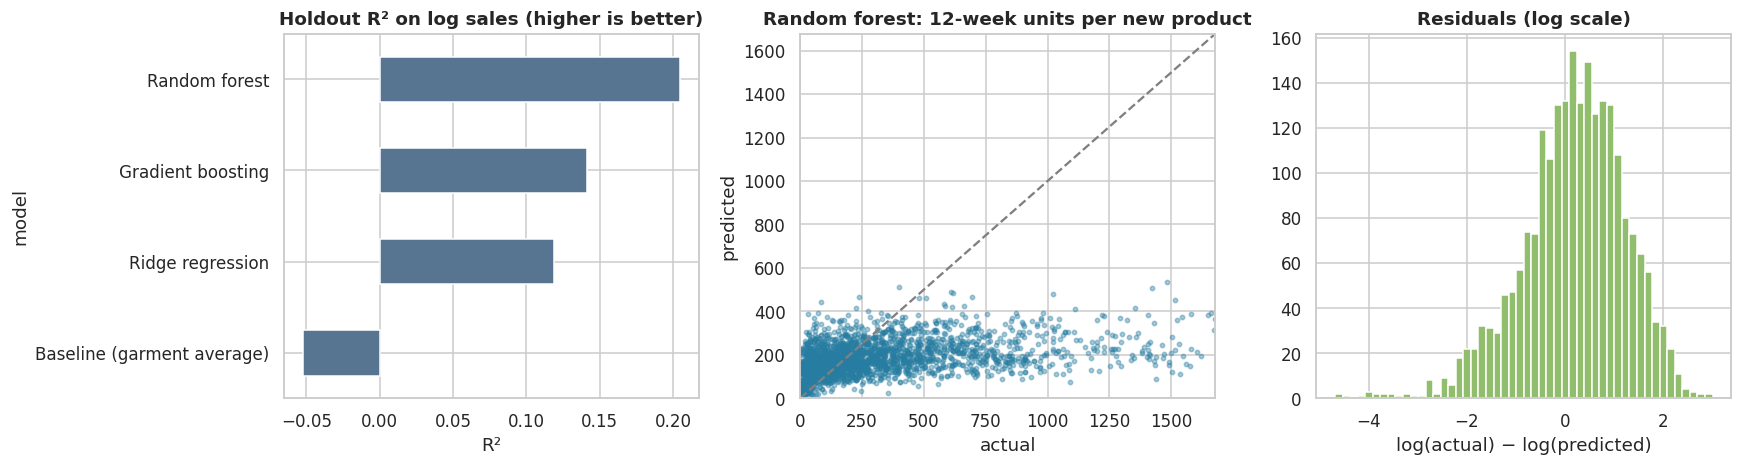

**What it shows:** How accurately each model predicts a new product's 12-week sales, the best model's predictions against reality, and its errors.  
**How we made it:** Trained ridge regression, random forest and gradient boosting on older launches and scored them on the most recent 20%, which they never saw; the baseline is the garment average.

Best on holdout: Random forest


In [40]:
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, roc_curve, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay


def wape(y_true, y_pred):
    return float(np.abs(y_true - y_pred).sum() / max(y_true.sum(), 1e-9))


def make_models(n_trees=300):
    return {
        "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=3.0)),
        "Random forest": RandomForestRegressor(n_estimators=n_trees, min_samples_leaf=3, max_features=0.4,
                                               n_jobs=-1, random_state=RANDOM_SEED),
        "Gradient boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, min_samples_leaf=20,
                                                           l2_regularization=1.0, random_state=RANDOM_SEED),
    }


def score(y_log_true, y_log_pred):
    u_true, u_pred = np.expm1(y_log_true), np.expm1(y_log_pred).clip(0)
    return {"R² (log)": r2_score(y_log_true, y_log_pred), "R² (units)": r2_score(u_true, u_pred),
            "MAE": mean_absolute_error(u_true, u_pred), "WAPE": wape(u_true, u_pred)}


cut = np.quantile(launch_ord, 0.8)
tr, te = launch_ord <= cut, launch_ord > cut
units_te = np.expm1(yp[te])

# Baseline: average (log) 12-week units for the same garment
base_tab = pd.Series(yp[tr]).groupby(products.loc[tr, "garment"].to_numpy()).mean()
base_pred = products.loc[te, "garment"].map(base_tab).fillna(yp[tr].mean()).to_numpy()
results = [{"model": "Baseline (garment average)", **score(yp[te], base_pred)}]
fitted, preds_log = {}, {}
for name, model in make_models().items():
    t0 = time.time()
    model.fit(Xp[tr], yp[tr])
    pl = model.predict(Xp[te])
    fitted[name], preds_log[name] = model, pl
    results.append({"model": name, **score(yp[te], pl), "fit seconds": round(time.time() - t0, 1)})
holdout_results = pd.DataFrame(results).set_index("model")

# Time-series cross-validation (expanding window over launch dates)
edges = np.quantile(launch_ord, [0.4, 0.6, 0.8, 1.0])
cv_rows = []
for i in range(3):
    trn = launch_ord <= edges[i]
    tst = (launch_ord > edges[i]) & (launch_ord <= edges[i + 1])
    for name, model in make_models(n_trees=150).items():
        model.fit(Xp[trn], yp[trn])
        cv_rows.append({"model": name, "fold": i + 1, "R² (log)": r2_score(yp[tst], model.predict(Xp[tst]))})
cv = pd.DataFrame(cv_rows).pivot(index="model", columns="fold", values="R² (log)")
holdout_results["CV R² (log, mean of 3 folds)"] = cv.mean(axis=1)
display(holdout_results.style.format("{:.3f}", na_rep="—").highlight_min(subset=["WAPE", "MAE"], color="#cde9d9")
        .highlight_max(subset=["R² (log)", "R² (units)"], color="#cde9d9"))
note("Accuracy of each demand model on launches it never saw (higher R², lower MAE and WAPE are better).",
     "Trained on the oldest 80% of launches, tested on the newest 20%, and repeated over 3 time-ordered folds for the cross-validation column.")

best_name = holdout_results.drop(index=holdout_results.index[0])["R² (log)"].idxmax()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
holdout_results["R² (log)"].sort_values().plot.barh(ax=axes[0], color="#577590")
axes[0].set(title="Holdout R² on log sales (higher is better)", xlabel="R²")
axes[1].scatter(np.expm1(yp[te]), np.expm1(preds_log[best_name]), s=8, alpha=0.4, color="#277da1")
lim = np.percentile(np.r_[np.expm1(yp[te]), np.expm1(preds_log[best_name])], 99)
axes[1].plot([0, lim], [0, lim], color="grey", ls="--"); axes[1].set(xlim=(0, lim), ylim=(0, lim))
axes[1].set(title=f"{best_name}: 12-week units per new product", xlabel="actual", ylabel="predicted")
resid = yp[te] - preds_log[best_name]
axes[2].hist(resid, bins=50, color="#90be6d")
axes[2].set(title="Residuals (log scale)", xlabel="log(actual) − log(predicted)")
show_fig("How accurately each model predicts a new product's 12-week sales, the best model's predictions against reality, and its errors.",
         'Trained ridge regression, random forest and gradient boosting on older launches and scored them on the most recent 20%, which they never saw; the baseline is the garment average.')
print(f"Best on holdout: {best_name}")

### 7c. What drives demand? Permutation importance and partial dependence
**Permutation importance**: how much the holdout error grows when one feature is shuffled. **Partial dependence**: how predicted demand moves as one feature changes, holding the rest fixed.

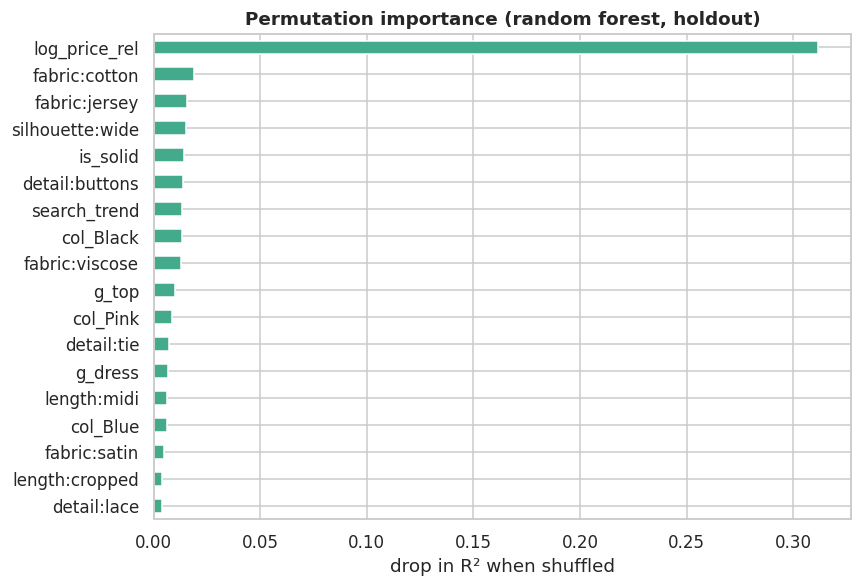

**What it shows:** Which inputs the demand model relies on most.  
**How we made it:** Shuffled one input at a time on the held-out launches and measured how much the model's R² dropped.

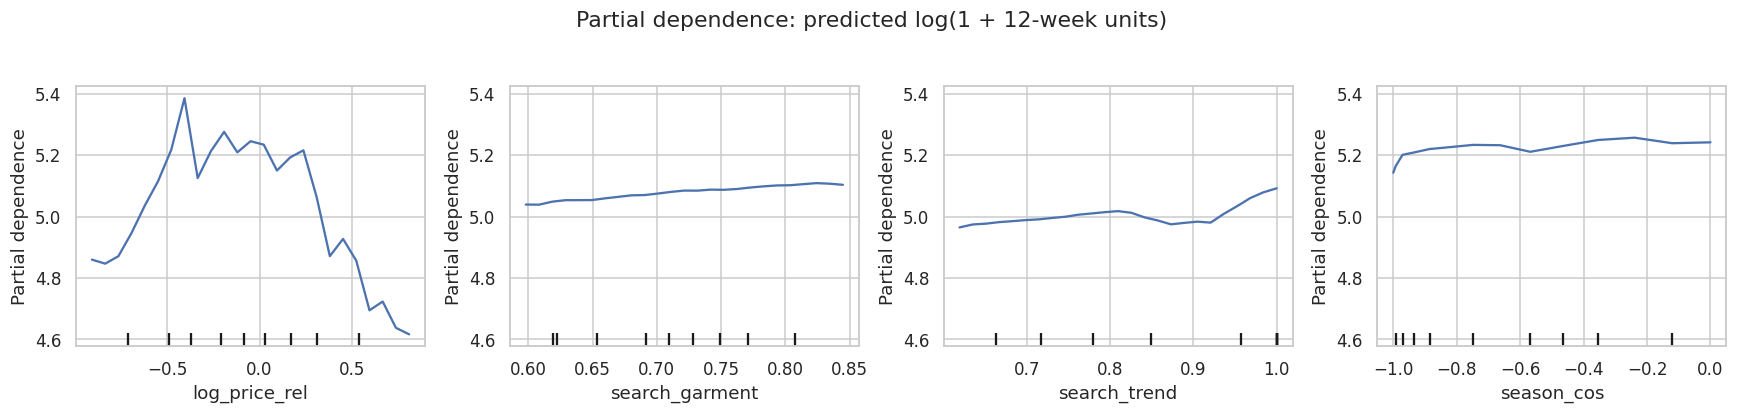

**What it shows:** How predicted sales change with price, garment search interest, the design's own trend interest and the season of launch.  
**How we made it:** Partial dependence: varied one input across its range while keeping every other input as it was, and averaged the random forest's predictions.

In [41]:
rf = fitted["Random forest"]
pi = permutation_importance(rf, Xp[te], yp[te], n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(18)
fig, ax = plt.subplots(figsize=(8, 5.5))
imp[::-1].plot.barh(ax=ax, color="#43aa8b")
ax.set(title="Permutation importance (random forest, holdout)", xlabel="drop in R² when shuffled")
show_fig('Which inputs the demand model relies on most.',
         "Shuffled one input at a time on the held-out launches and measured how much the model's R² dropped.")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
PartialDependenceDisplay.from_estimator(rf, Xp[te], ["log_price_rel", "search_garment", "search_trend", "season_cos"],
                                        ax=ax, kind="average", grid_resolution=25)
fig.suptitle("Partial dependence: predicted log(1 + 12-week units)", y=1.04)
show_fig("How predicted sales change with price, garment search interest, the design's own trend interest and the season of launch.",
         "Partial dependence: varied one input across its range while keeping every other input as it was, and averaged the random forest's predictions.")
residual_sigma = float(np.std(yp[te] - preds_log["Random forest"]))

## 8. "Hit" classifier: will a new design be a top seller?
A product is a **hit** if its first 8 weeks put it in the top 25% of its garment type. Three classifiers predict this from launch-time features only. Business use: each brief gets a **hit probability**.

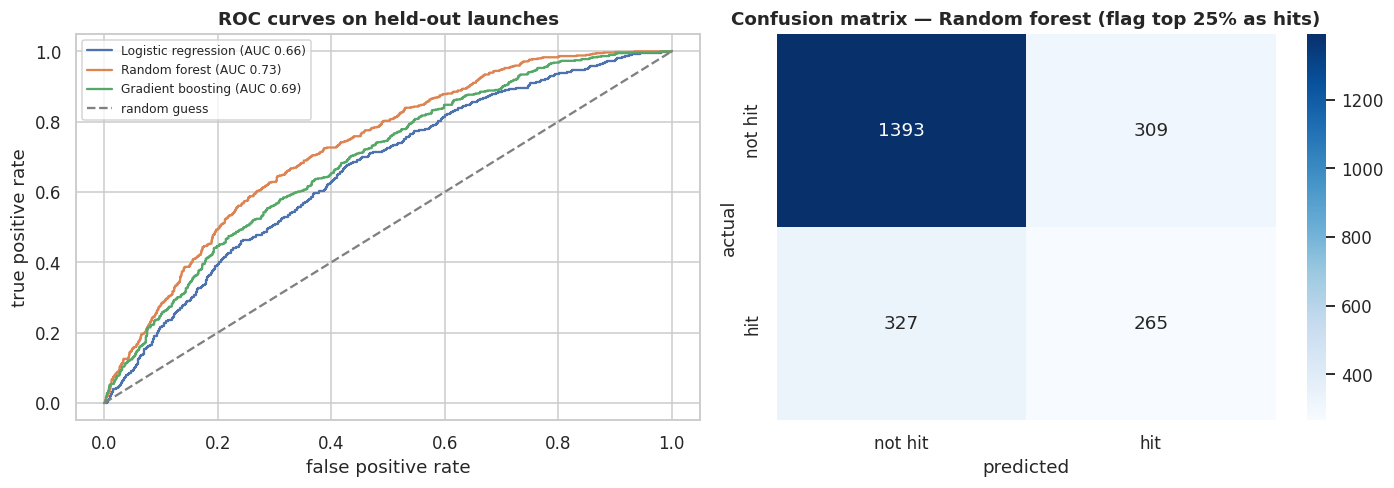

**What it shows:** How well three models spot future best-sellers (left), and the best model's hits and misses (right).  
**How we made it:** Labelled the top 25% of each garment's launches by first-8-week sales as hits, trained classifiers on older launches and tested them on the newest 20%.

,ROC AUC,precision,recall,F1
model,,,,
Logistic regression,0.658,0.404,0.392,0.398
Random forest,0.727,0.462,0.448,0.455
Gradient boosting,0.689,0.436,0.422,0.429


**What it shows:** How well each classifier separates future best-sellers from the rest (AUC 0.5 = guessing, 1.0 = perfect).  
**How we made it:** Scored on the newest 20% of launches; precision, recall and F1 count the top 25% of predicted probabilities as predicted hits.

In [42]:
L = products.copy()
L["hit"] = (L["units_8w"] >= L.groupby("garment")["units_8w"].transform(lambda s: s.quantile(0.75))).astype(int)
CLS_FEATURES = FEATURES   # same launch-time features as the demand model
Xc, yc = Xp[CLS_FEATURES], L["hit"].to_numpy()
lo = L["launch_week"].map(pd.Timestamp.toordinal).to_numpy()
ctr, cte = lo <= np.quantile(lo, 0.8), lo > np.quantile(lo, 0.8)

classifiers = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_SEED,
                                            class_weight="balanced_subsample"),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RANDOM_SEED),
}
cls_rows, probs = [], {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, clf in classifiers.items():
    clf.fit(Xc[ctr], yc[ctr])
    p = clf.predict_proba(Xc[cte])[:, 1]
    probs[name] = p
    thr = np.quantile(p, 0.75)
    pred = (p >= thr).astype(int)
    cls_rows.append({"model": name, "ROC AUC": roc_auc_score(yc[cte], p), "precision": precision_score(yc[cte], pred),
                     "recall": recall_score(yc[cte], pred), "F1": f1_score(yc[cte], pred)})
    fpr, tpr, _ = roc_curve(yc[cte], p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {cls_rows[-1]['ROC AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", label="random guess")
axes[0].set(title="ROC curves on held-out launches", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(fontsize=8)
cls_results = pd.DataFrame(cls_rows).set_index("model")
best_cls = cls_results["ROC AUC"].idxmax()
pb = probs[best_cls]
cm = confusion_matrix(yc[cte], (pb >= np.quantile(pb, 0.75)).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], xticklabels=["not hit", "hit"], yticklabels=["not hit", "hit"])
axes[1].set(title=f"Confusion matrix — {best_cls} (flag top 25% as hits)", xlabel="predicted", ylabel="actual")
show_fig("How well three models spot future best-sellers (left), and the best model's hits and misses (right).",
         "Labelled the top 25% of each garment's launches by first-8-week sales as hits, trained classifiers on older launches and tested them on the newest 20%.")
display(cls_results.style.format("{:.3f}").highlight_max(color="#cde9d9"))
note("How well each classifier separates future best-sellers from the rest (AUC 0.5 = guessing, 1.0 = perfect).",
     "Scored on the newest 20% of launches; precision, recall and F1 count the top 25% of predicted probabilities as predicted hits.")
hit_model = classifiers[best_cls].fit(Xc, yc)   # refit on everything for scoring briefs

## 9. Style clusters: what families of product does H&M sell, and which perform?
**K-means** on the design attributes (silhouette, length, details, fabric, colour, price, sustainable, convertible; garment type left out on purpose) groups the catalogue into style families that cut across garment types; **PCA** projects them to 2D for plotting. The heatmaps show what defines each cluster, which garments fall in it, and how well it sold.

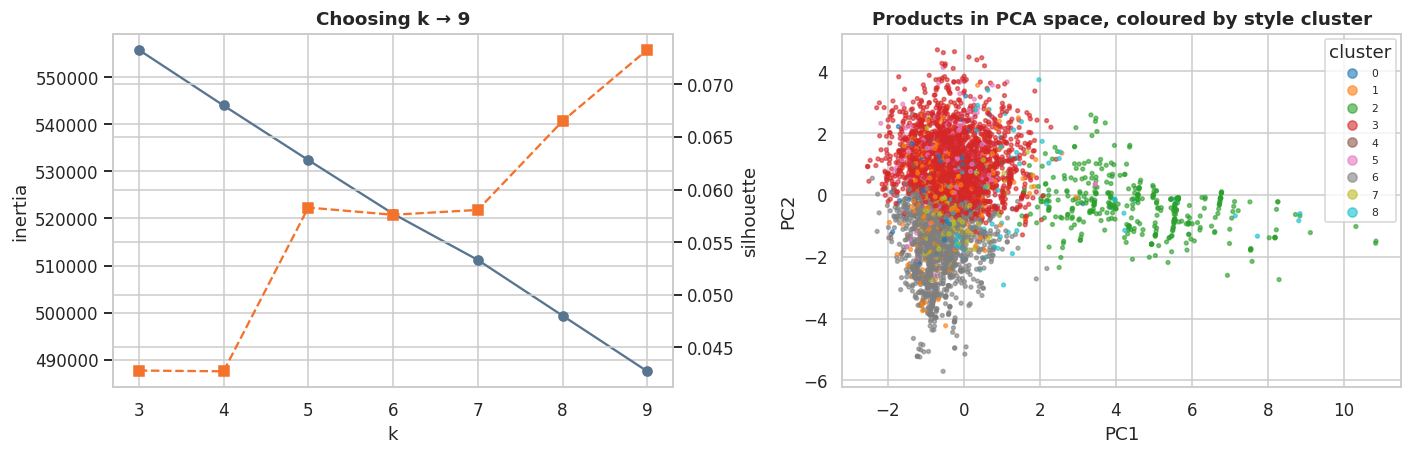

**What it shows:** The style families in H&M's catalogue and how products group together.  
**How we made it:** Clustered products on their design attributes with k-means (k chosen by silhouette score) and projected them to 2D with PCA for plotting.

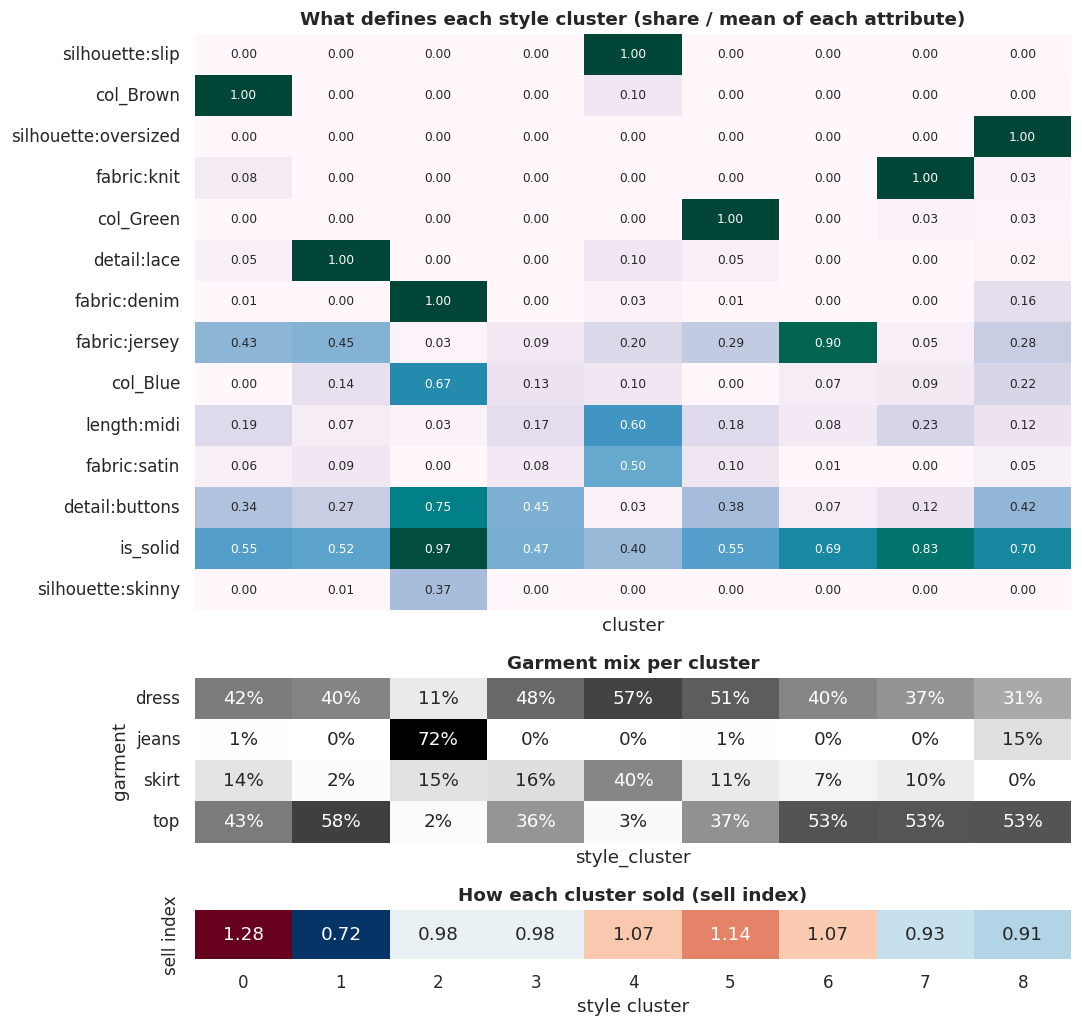

**What it shows:** What defines each style family, which garments it contains, and how well it sold.  
**How we made it:** Averaged each attribute, the garment mix and the sell index within each k-means cluster.

In [43]:
from sklearn.decomposition import PCA

# Cluster on design attributes only (not garment type), then see which garments fall in each style family
style_cols = [c for c in STATIC if not c.startswith("g_") and c in static_X.columns]
S = StandardScaler().fit_transform(static_X[style_cols])
ks = range(3, 10)
inertia, sils = [], []
sub = rng.choice(len(S), size=min(5000, len(S)), replace=False)
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_SEED).fit(S)
    inertia.append(m.inertia_)
    sils.append(silhouette_score(S[sub], m.labels_[sub]))
style_k = list(ks)[int(np.argmax(sils))]
style_km = KMeans(n_clusters=style_k, n_init=10, random_state=RANDOM_SEED).fit(S)
pcs = PCA(n_components=2, random_state=RANDOM_SEED).fit_transform(S)
products["style_cluster"] = style_km.labels_

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(list(ks), inertia, "o-", color="#577590", label="inertia (elbow)")
ax2 = axes[0].twinx()
ax2.plot(list(ks), sils, "s--", color="#f3722c", label="silhouette")
axes[0].set(title=f"Choosing k → {style_k}", xlabel="k", ylabel="inertia"); ax2.set_ylabel("silhouette")
sc = axes[1].scatter(pcs[sub, 0], pcs[sub, 1], c=style_km.labels_[sub], cmap="tab10", s=6, alpha=0.6)
axes[1].legend(*sc.legend_elements(), title="cluster", fontsize=7, loc="best")
axes[1].set(title="Products in PCA space, coloured by style cluster", xlabel="PC1", ylabel="PC2")
show_fig("The style families in H&M's catalogue and how products group together.",
         'Clustered products on their design attributes with k-means (k chosen by silhouette score) and projected them to 2D with PCA for plotting.')

prof = static_X[style_cols].assign(cluster=style_km.labels_).groupby("cluster").mean()
spread_ = (prof - static_X[style_cols].mean()).abs().max()
top_attrs = spread_.sort_values(ascending=False).head(14).index
prof_show = prof[top_attrs].T
garment_mix = pd.crosstab(products["garment"], products["style_cluster"], normalize="columns")
perf = products.groupby("style_cluster")["sell_index"].mean().to_frame("sell index").T
fig, axes = plt.subplots(3, 1, figsize=(10, 9.5), gridspec_kw={"height_ratios": [len(prof_show), 4, 1.2]}, sharex=True)
sns.heatmap(prof_show, annot=True, fmt=".2f", cmap="PuBuGn", ax=axes[0], cbar=False, annot_kws={"size": 8})
axes[0].set_title("What defines each style cluster (share / mean of each attribute)")
sns.heatmap(garment_mix, annot=True, fmt=".0%", cmap="Greys", ax=axes[1], cbar=False)
axes[1].set_title("Garment mix per cluster")
sns.heatmap(perf, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, ax=axes[2], cbar=False)
axes[2].set(title="How each cluster sold (sell index)", xlabel="style cluster")
show_fig('What defines each style family, which garments it contains, and how well it sold.',
         'Averaged each attribute, the garment mix and the sell index within each k-means cluster.')

## 10. Customer votes (from the Google Sheet)
The voting page writes each vote to the `votes` tab. Each shopper (anonymous `voter_id`) counts once per design: their latest vote. A design's approval (share rating it 4 or 5 out of 5) is scored with the **Wilson lower bound**, so 9 of 10 approvals doesn't beat 180 of 200.

In [44]:
def open_sheet():
    if not SHEET_URL:
        return None
    import gspread
    if IN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        import google.auth
        creds, _ = google.auth.default()
        gc = gspread.authorize(creds)
    else:
        gc = gspread.service_account()
    return gc.open_by_url(SHEET_URL)


def read_tab(sh, name: str) -> pd.DataFrame:
    if sh is None:
        local = OUT_DIR / f"{name}.csv"
        return pd.read_csv(local) if local.exists() else pd.DataFrame()
    try:
        return pd.DataFrame(sh.worksheet(name).get_all_records())
    except Exception:
        return pd.DataFrame()


def wilson_low(pos, n, z=1.64):
    pos, n = np.asarray(pos, float), np.asarray(n, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = np.where(n > 0, pos / n, 0)
        lo = (p + z * z / (2 * n) - z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / (1 + z * z / n)
    return np.where(n > 0, lo, 0.0)


sheet = open_sheet()
votes = read_tab(sheet, "votes")
previous_designs = read_tab(sheet, "designs")
if len(votes):
    votes["timestamp"] = pd.to_datetime(votes["timestamp"], errors="coerce")
    votes = votes.sort_values("timestamp").drop_duplicates(["voter_id", "item_id"], keep="last")
    dv = votes[votes["type"] == "design"].copy()
    dv["rating"] = pd.to_numeric(dv["rating"], errors="coerce")
    dv["approve"] = (dv["rating"] >= 4).astype(int)
    dv["price_yes"] = dv["price_answer"].eq("yes").astype(int)
    design_votes = dv.groupby("item_id").agg(n_votes=("approve", "size"), approvals=("approve", "sum"),
                                             avg_rating=("rating", "mean"), price_yes=("price_yes", "mean"))
    design_votes["approval"] = design_votes["approvals"] / design_votes["n_votes"]
    design_votes["wilson_low"] = wilson_low(design_votes["approvals"], design_votes["n_votes"])
    colour_votes = dv[dv["colour"].astype(str).str.len() > 0].groupby(["item_id", "colour"]).size().rename("n").reset_index()
    tv = votes[votes["type"] == "trend"].copy()
    tv["hot"] = tv["answer"].eq("hot").astype(int)
    trend_votes = tv.groupby("item_id").agg(n_votes=("hot", "size"), hot=("hot", "sum"))
    trend_votes["hot_share"] = trend_votes["hot"] / trend_votes["n_votes"]
    trend_votes["wilson_low"] = wilson_low(trend_votes["hot"], trend_votes["n_votes"])
    print(f"{len(votes):,} votes from {votes['voter_id'].nunique():,} shoppers")
    display(design_votes.sort_values("wilson_low", ascending=False).round(2))
    note("Customer approval for each design that has been posted for voting.",
         "Kept each shopper's latest vote per design; approval = share rating 4–5 of 5, ranked with the Wilson lower bound so small samples aren't over-trusted.")
    if len(colour_votes):
        cv_pivot = colour_votes.pivot(index="item_id", columns="colour", values="n").fillna(0)
        fig, ax = plt.subplots(figsize=(min(16, 2 + cv_pivot.shape[1]), 0.5 * len(cv_pivot) + 2))
        sns.heatmap(cv_pivot.div(cv_pivot.sum(axis=1), axis=0), annot=cv_pivot.astype(int), fmt="d", cmap="RdPu", ax=ax)
        ax.set_title("Colour votes per design (colour = share of that design's votes, number = votes)")
        show_fig('Which colour customers picked for each design.',
         'Counted colour choices from the voting page, one vote per shopper per design (their latest).')
else:
    design_votes = pd.DataFrame(columns=["n_votes", "approvals", "avg_rating", "price_yes", "approval", "wilson_low"])
    colour_votes = pd.DataFrame(columns=["item_id", "colour", "n"])
    trend_votes = pd.DataFrame(columns=["n_votes", "hot", "hot_share", "wilson_low"])
    print("No customer votes yet — briefs are scored on sales, trends and Pantone only. "
          "Once shoppers vote, rerun the notebook and their votes enter the score.")

No customer votes yet — briefs are scored on sales, trends and Pantone only. Once shoppers vote, rerun the notebook and their votes enter the score.


## 11. Generate and score new designs
The engine combines building blocks into candidate designs: a **simple, sleek base** (garment + silhouette + length + fabric) with **one signature detail**, in a colourway, optionally convertible and/or in a sustainable material. Each candidate is scored on six things (0–100):

| Score | Weight | Source |
|---|---|---|
| Trend | 25% | Google Trends projection at launch for its linked keywords (silhouette, length, detail, fabric) |
| Hit probability | 20% | Classifier from section 8 |
| Demand | 15% | Demand model from section 7, vs the median candidate of the same garment |
| Sales history | 15% | Sell index of past H&M products sharing its attributes |
| Customer votes | 15% | Wilson-scored approval from the voting page, ranked among voted designs; unvoted designs sit at a neutral 50 (with no votes at all, this weight moves to the others) |
| Novelty | 10% | Penalises combinations H&M has sold often; very common ones are excluded |

**Colourway** is then chosen per design from Pantone's current palettes, how that colour sold for the garment in H&M's history, and customers' colour votes.

In [45]:
LIBRARY = {
    "dress": {"silhouettes": ["wrap", "a-line", "fitted", "slip"], "lengths": ["mini", "midi", "maxi"],
              "details": ["puff-sleeve", "ruffle", "smocking", "slit", "cut-out", "tie", "buttons", "lace"],
              "fabrics": ["satin", "linen", "viscose", "jersey", "cotton"]},
    "top": {"silhouettes": ["fitted", "wrap", "oversized"], "lengths": ["cropped", ""],
            "details": ["puff-sleeve", "ruffle", "lace", "corset", "tie", "sheer", "buttons", "cut-out"],
            "fabrics": ["satin", "linen", "cotton", "jersey", "viscose"]},
    "jeans": {"silhouettes": ["wide", "straight", "barrel", "flare", "mom", "slim"], "lengths": [""],
              "details": ["slit", "pleats", "buttons", "cut-out", "tie"], "fabrics": ["denim"]},
    "skirt": {"silhouettes": ["a-line", "wrap", "fitted", "slip"], "lengths": ["mini", "midi", "maxi"],
              "details": ["slit", "ruffle", "pleats", "buttons", "tie", "lace"],
              "fabrics": ["satin", "linen", "denim", "viscose", "cotton"]},
}
COLOURWAYS = {  # name: (hex, H&M colour group, Pantone code or "")
    "Cloud Dancer": ("#F0EEE9", "Off White", "11-4201"), "Princess Blue": ("#00539C", "Blue", "19-4150"),
    "Chili Pepper": ("#9B1B30", "Dark Red", "19-1557"), "Hibiscus": ("#DD3848", "Red", "18-1762"),
    "Waterfall": ("#3AB0A2", "Turquoise", "15-5516"), "Lavender Oil": ("#C2A6CF", "Light Purple", "15-3615"),
    "Anise Flower": ("#E8E6B4", "Light Yellow", "12-0717"), "Rosy Future": ("#E5A3B4", "Pink", "15-1910"),
    "Langoustino": ("#CA6C56", "Dark Orange", "16-1440"), "Daiquiri Green": ("#D8E39A", "Light Green", "12-0435"),
    "Tarragon": ("#A4AE77", "Greenish Khaki", "15-0326"), "Blue Indigo": ("#49516D", "Dark Blue", "19-3928"),
    "Dolphin": ("#716675", "Grey", "16-2901"), "Black": ("#1C1C1C", "Black", ""),
    "Light-wash denim": ("#A7BFD8", "Light Blue", ""), "Mid-wash denim": ("#5A7DA3", "Blue", ""),
    "Dark-wash denim": ("#2F3F5C", "Dark Blue", ""),
}
JEANS_COLOURS = ["Light-wash denim", "Mid-wash denim", "Dark-wash denim", "Black", "Cloud Dancer", "Tarragon", "Blue Indigo"]
MULTIWAY_OPTIONS = {
    "dress": [("Convertible straps", "Straps clip to front and back loops: wear them straight, crossed at the back or as a halter.")],
    "top": [("Reversible neckline", "Wear with the V-neck at the front, or turn it round for a high neck and open back."),
            ("Tie hem", "Leave the hem long and loose, or knot the ties at the waist for a cropped look.")],
    "jeans": [("Zip-off hem", "A hidden zip below the knee turns full-length jeans into cropped ones.")],
    "skirt": [("Skirt-to-dress", "The elasticated waistband pulls up over the bust: wear it as a skirt or a strapless dress."),
              ("Detachable tier", "Unbutton the bottom tier to go from midi to mini.")],
}
SUST_FABRIC = {"satin": "recycled polyester satin", "linen": "organic linen", "viscose": "LENZING™ ECOVERO™ viscose",
               "jersey": "organic cotton jersey", "cotton": "organic cotton", "denim": "recycled cotton denim"}
PRICE_BANDS = {"dress": (25, 45), "top": (15, 30), "jeans": (30, 45), "skirt": (20, 35)}  # € assumption (H&M public price range)
FABRIC_PREMIUM = {"satin": 0.15, "linen": 0.12, "viscose": 0.0, "jersey": -0.1, "cotton": 0.0, "denim": 0.0}

# Colour family lookup (H&M colour group → perceived colour master) learned from the catalogue
colour_family_of = articles.groupby("colour")["colour_family"].agg(lambda s: s.value_counts().index[0]).to_dict()


def design_id(c: dict) -> str:
    key = "|".join(str(c[k]) for k in ("garment", "silhouette", "length", "detail", "fabric", "multiway", "sustainable"))
    return "D" + hashlib.md5(key.encode()).hexdigest()[:6].upper()


def candidate_rows() -> list[dict]:
    rows = []
    for g, lib in LIBRARY.items():
        for sil in lib["silhouettes"]:
            for length in lib["lengths"]:
                for det in lib["details"]:
                    for fab in lib["fabrics"]:
                        mw_opts = [o for o in MULTIWAY_OPTIONS[g] if not (o[0] == "Detachable tier" and length != "midi")
                                   and not (o[0] == "Skirt-to-dress" and length == "mini")]
                        for mw in ([None] + mw_opts[:1]):
                            for sust in (False, True):
                                rows.append({"garment": g, "silhouette": sil, "length": length, "detail": det,
                                             "fabric": fab, "multiway": mw[0] if mw else "",
                                             "conversion": mw[1] if mw else "", "sustainable": sust})
    return rows


def as_feature_row(c: dict, colour: str) -> dict:
    r = {a: 0 for a in ATTRS}
    r[f"silhouette:{c['silhouette']}"] = 1
    if c["length"]:
        r[f"length:{c['length']}"] = 1
    r[f"detail:{c['detail']}"] = 1
    r[f"fabric:{c['fabric']}"] = 1
    lo_, hi_ = PRICE_BANDS[c["garment"]]
    mid = (lo_ + hi_) / 2
    price = mid * (1 + FABRIC_PREMIUM[c["fabric"]] + 0.08 * c["sustainable"] + 0.1 * bool(c["multiway"]))
    price = float(np.clip(round(price) - 0.01, lo_ - 0.01, hi_ + 4.99))
    hm_group = COLOURWAYS[colour][1]
    r.update({"garment": c["garment"], "colour": hm_group, "colour_family": colour_family_of.get(hm_group, "Black"),
              "is_solid": 1, "is_sustainable": int(c["sustainable"]), "is_multiway": int(bool(c["multiway"])),
              "price_rel": price / mid, "price_eur": price})
    return r


cands = pd.DataFrame(candidate_rows())
cands["design_id"] = [design_id(r) for r in cands.to_dict("records")]
print(f"{len(cands):,} candidate designs generated")

# Novelty: how often has H&M sold this exact base (garment+silhouette+detail+fabric)?
combo_counts = {}
for g in GARMENTS:
    sub_p = products[products["garment"] == g]
    for sil in LIBRARY[g]["silhouettes"]:
        for det in LIBRARY[g]["details"]:
            for fab in LIBRARY[g]["fabrics"]:
                m = sub_p[f"silhouette:{sil}"].eq(1) & sub_p[f"detail:{det}"].eq(1) & sub_p[f"fabric:{fab}"].eq(1)
                combo_counts[(g, sil, det, fab)] = int(m.sum())
cands["past_count"] = [combo_counts[(r.garment, r.silhouette, r.detail, r.fabric)] for r in cands.itertuples()]


PLURAL = {"dress": "dresses", "top": "tops", "jeans": "jeans", "skirt": "skirts"}
DETAIL_PHRASE = {"puff-sleeve": "puff sleeves", "ruffle": "a ruffle edge", "smocking": "a smocked bodice", "slit": "a side slit",
                 "cut-out": "a single cut-out", "tie": "a tie detail", "buttons": "a statement button line", "lace": "a lace trim",
                 "corset": "corset seaming", "sheer": "a sheer panel", "pleats": "pressed front pleats"}


def attr_phrase(key: str) -> str:
    cat, val = key.split(":")
    if cat == "detail":
        return DETAIL_PHRASE.get(val, val)
    if cat == "silhouette":
        return {"a-line": "an A-line cut", "slip": "a slip cut", "wide": "a wide leg", "straight": "a straight leg",
                "barrel": "a barrel leg", "flare": "a flared leg", "mom": "a mom fit", "slim": "a slim fit",
                "oversized": "an oversized cut"}.get(val, f"a {val} cut")
    if cat == "length":
        return f"{val} length" if val != "cropped" else "a cropped length"
    return f"{val} fabric"


def attribute_love(c) -> tuple[float, list[str]]:
    """Sell index of past products sharing each attribute (shrunk to 1.0 when few products)."""
    sub_p = products[products["garment"] == c["garment"]]
    vals, notes = [], []
    for key in [f"silhouette:{c['silhouette']}", f"detail:{c['detail']}", f"fabric:{c['fabric']}"] + \
               ([f"length:{c['length']}"] if c["length"] else []):
        m = sub_p[sub_p[key] == 1]
        n = len(m)
        idx = (m["sell_index"].sum() + 20 * 1.0) / (n + 20)   # shrink towards 1.0
        vals.append(idx)
        if n >= 15 and abs(idx - 1) > 0.06:
            notes.append(f"Past H&M {PLURAL[c['garment']]} with {attr_phrase(key)} sold {m['sell_index'].mean():.2f}× "
                         f"their average ({n} products)")
    for flag, label in (("sustainable", "is_sustainable"), ("multiway", "is_multiway")):
        if c[flag]:
            m = sub_p[sub_p[label] == 1]
            if len(m) >= 10:
                vals.append((m["sell_index"].sum() + 20) / (len(m) + 20))
    return float(np.mean(vals)), notes


TT = trend_table.set_index("keyword")


def trend_signal(c) -> tuple[float, list[str], list[str]]:
    """Projected search interest at launch for the design's linked keywords (colour handled separately)."""
    attrs = {f"silhouette:{c['silhouette']}": 1, f"detail:{c['detail']}": 1, f"fabric:{c['fabric']}": 1}
    if c["length"]:
        attrs[f"length:{c['length']}"] = 1
    notes, statuses, vals = [], [], []
    for kw in matched_keywords(c["garment"], attrs):
        row = TT.loc[kw]
        vals.append(min(row["at_launch"], 3.0))
        statuses.append(row["status"])
        notes.append(f"“{kw}” search interest {row['status']} ({row['yoy_change_pct']:+.0f}% YoY), "
                     f"projected {row['at_launch']:.2f}× its average at launch")
    search = np.mean(vals) if vals else 1.0
    return float(min(search / 1.5, 1.6)), notes, statuses


def colour_note(colour: str) -> str:
    code = COLOURWAYS[colour][2]
    if not code:
        return ""
    pal = pantone.set_index("pantone_name")["palette"].get(colour, "")
    return f"{colour} (PANTONE {code}) is in Pantone's {pal} palette" if pal else ""


def default_colour(c) -> str:
    return "Mid-wash denim" if c["garment"] == "jeans" else "Black"


# Stage 1: score every base design in a neutral colour
base = cands.to_dict("records")
static_rows = pd.DataFrame([as_feature_row(c, default_colour(c)) for c in base])
static_rows["trend_kws"] = [matched_keywords(r["garment"], r) for r in static_rows.to_dict("records")]
proj_series = {k: v.to_dict() for k, v in projections.items()}


def candidate_X(rows: pd.DataFrame) -> pd.DataFrame:
    """Launch-time features for new designs: projected search interest over the launch window, no lockdown."""
    X_ = pd.concat([static_features(rows), launch_features(rows, LAUNCH_WEEK, proj_series)], axis=1)
    X_["lockdown"] = 0.0
    return X_[FEATURES]


rf_full = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.4, n_jobs=-1,
                                random_state=RANDOM_SEED).fit(Xp, yp)
cand_X = candidate_X(static_rows)
static_rows["demand_12w"] = np.expm1(rf_full.predict(cand_X)).clip(0)
static_rows["hit_prob"] = hit_model.predict_proba(cand_X[CLS_FEATURES])[:, 1]
cands = pd.concat([cands, static_rows[["demand_12w", "hit_prob", "price_eur"]]], axis=1)
loves = [attribute_love(c) for c in base]
cands["history_idx"] = [l[0] for l in loves]
cands["history_notes"] = [l[1] for l in loves]


def pct_rank(s: pd.Series) -> pd.Series:
    return s.rank(pct=True) * 100


cands["demand_score"] = cands.groupby("garment")["demand_12w"].transform(pct_rank)
cands["hit_score"] = cands.groupby("garment")["hit_prob"].transform(pct_rank)
cands["history_score"] = cands.groupby("garment")["history_idx"].transform(pct_rank)
cands["novelty_score"] = (100 * np.exp(-cands["past_count"] / 8)).round(1)
cands = cands[cands["past_count"] < 40]   # skip combinations H&M has sold dozens of times
print(f"{len(cands):,} candidates after the novelty filter")

4,200 candidate designs generated
4,104 candidates after the novelty filter


In [46]:
# Stage 2: rank colourways per garment (Pantone + colour sales history + colour votes) and add trend and vote scores
colour_hist = products.groupby(["garment", "colour"])["sell_index"].agg(["sum", "size"])
colour_vote_share = (colour_votes.groupby("colour")["n"].sum() / max(colour_votes["n"].sum(), 1)) if len(colour_votes) else pd.Series(dtype=float)


def colour_score(garment: str, colour: str) -> float:
    grp = COLOURWAYS[colour][1]
    s, n = colour_hist.loc[(garment, grp)] if (garment, grp) in colour_hist.index else (0.0, 0)
    hist = (s + 20) / (n + 20)
    pan = pantone_score.get(grp, 0.0) if COLOURWAYS[colour][2] else 0.0
    vote = colour_vote_share.get(colour, 0.0)
    return hist + 0.35 * pan + 2.0 * vote


VOTE_W = 0.15 if len(design_votes) else 0.0
WEIGHTS = {"trend": 0.25, "hit": 0.20, "demand": 0.15, "history": 0.15, "novelty": 0.10}
scale = (1 - VOTE_W) / sum(WEIGHTS.values())
COLOUR_RANK = {g: sorted(JEANS_COLOURS if g == "jeans" else [k for k in COLOURWAYS if "denim" not in k],
                         key=lambda col: colour_score(g, col), reverse=True) for g in GARMENTS}
# Votes on the same 0–100 scale as the other scores: percentile of the Wilson lower bound among voted designs
VOTE_PCT = (design_votes["wilson_low"].rank(pct=True) * 100) if len(design_votes) else pd.Series(dtype=float)
records = []
for c in cands.to_dict("records"):
    t_val, t_notes, statuses = trend_signal(c)
    has_votes = c["design_id"] in design_votes.index
    c.update({"colour_rank": COLOUR_RANK[c["garment"]], "trend_value": t_val, "trend_notes": t_notes,
              "trend_statuses": statuses,
              "vote_score": float(VOTE_PCT[c["design_id"]]) if has_votes else np.nan,
              "n_votes": int(design_votes.loc[c["design_id"], "n_votes"]) if has_votes else 0})
    records.append(c)
scored = pd.DataFrame(records)
scored = scored[~scored["trend_statuses"].apply(lambda s: len(s) > 0 and sum(x == "fading" for x in s) > len(s) / 2)].copy()   # drop pieces riding mostly fading trends
scored["trend_score"] = scored.groupby("garment")["trend_value"].transform(pct_rank)
vote_filled = scored["vote_score"].fillna(50)   # designs nobody has voted on yet are neutral
scored["total_score"] = (scale * (WEIGHTS["trend"] * scored["trend_score"] + WEIGHTS["hit"] * scored["hit_score"]
                                  + WEIGHTS["demand"] * scored["demand_score"] + WEIGHTS["history"] * scored["history_score"]
                                  + WEIGHTS["novelty"] * scored["novelty_score"]) + VOTE_W * vote_filled).round(1)
print(f"{len(scored):,} candidates scored (pieces tied mostly to fading trends removed)")
display(scored.groupby("garment").size().rename("candidates").to_frame())

3,664 candidates scored (pieces tied mostly to fading trends removed)


,candidates
garment,
dress,1796
jeans,92
skirt,928
top,848


### Selecting a balanced set of 12
Greedy selection by score with variety rules: 3 per garment; within a garment no repeated silhouette, signature detail or fabric and at most two of the same length; at most three pieces in the same fabric overall (denim jeans excepted); overall a detail at most twice and a colourway at most twice (a design moves to its next-best colour when its first choice is taken); then swaps in the best convertible / sustainable alternatives until the quotas are met, losing as little score as possible. If the strict rules can't fill all 12 slots (for example when many candidates ride fading trends), the caps on repeated colours and details are relaxed one step at a time.

12 briefs selected using variety-rule level 0 (strict).


,garment,name,colour,material,multiway,price_eur,total_score,trend_score,hit_prob,demand_score,history_score,novelty_score
0,dress,A-line midi dress with a statement button line,Langoustino,organic linen,Convertible straps,€45.99,97.6,98,50%,100,93,100
1,dress,Fitted midi dress with a smocked bodice,Tarragon,viscose crêpe,Convertible straps,€37.99,82.0,81,44%,90,84,78
2,dress,Slip mini dress with a ruffle edge,Cloud Dancer,cotton jersey,Convertible straps,€34.99,68.3,47,45%,62,68,100
3,top,Oversized top with a statement button line,Langoustino,organic linen,,€26.99,92.3,83,58%,98,91,100
4,top,Fitted top with corset seaming,Tarragon,viscose crêpe,,€21.99,88.2,67,59%,95,96,100
5,top,Wrap top with a lace trim,Chili Pepper,cotton jersey,,€19.99,84.5,95,53%,65,88,69
6,jeans,Barrel-leg jeans with a tie detail,Cloud Dancer,cotton denim,,€37.99,74.4,92,36%,84,31,100
7,jeans,Straight-leg jeans with a side slit,Blue Indigo,recycled cotton denim,,€39.99,66.3,64,37%,69,44,78
8,jeans,Slim jeans with pressed front pleats,Black,cotton denim,,€37.99,64.6,16,38%,79,75,100
9,skirt,Slip midi skirt with a tie detail,Anise Flower,organic linen,Skirt-to-dress,€35.99,83.7,76,47%,87,91,100


**What it shows:** The 12 design briefs: what to make, in which colour and material, at what price, and how each scored.  
**How we made it:** Generated thousands of candidate designs from building blocks, scored them with the models and trend data, and picked a balanced set with variety rules.

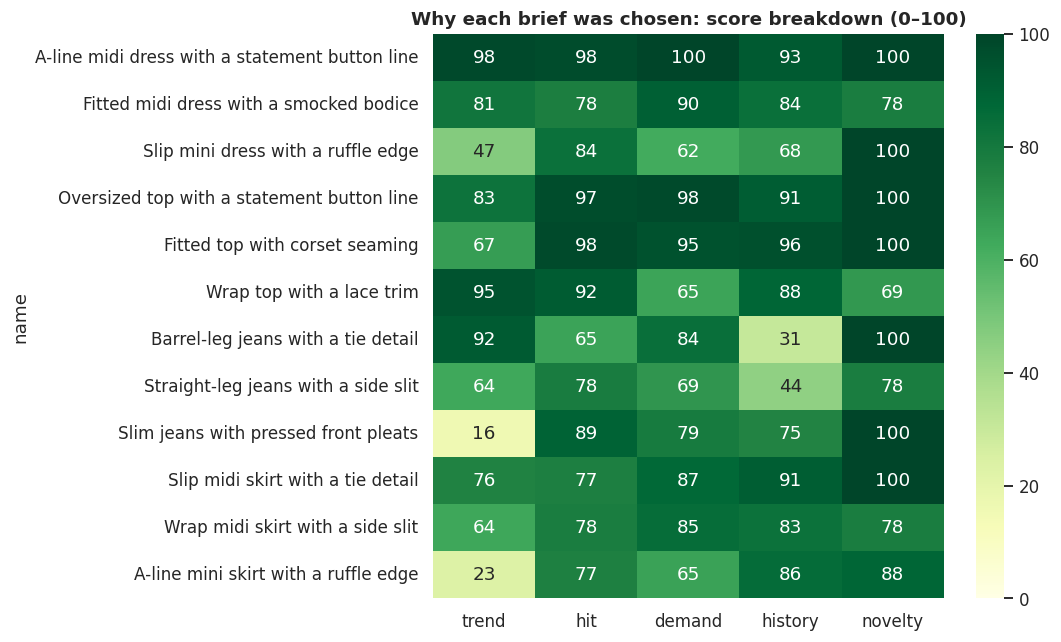

**What it shows:** Why each design was chosen: its score on each criterion.  
**How we made it:** Each criterion is a 0–100 percentile among candidates of the same garment; the total weights trend 25%, hit probability 20%, demand 15%, sales history 15%, customer votes 15% and novelty 10%.

In [47]:
# Variety rules, from strict to relaxed; the strictest level that still fills every garment is used
RULE_LEVELS = [
    {"max_colour": 2, "max_detail": 2, "length_rule": True, "fabric_per_garment": 1, "fabric_total": 3},   # strict
    {"max_colour": 3, "max_detail": 3, "length_rule": True, "fabric_per_garment": 2, "fabric_total": 4},
    {"max_colour": 4, "max_detail": 4, "length_rule": False, "fabric_per_garment": 2, "fabric_total": 6},  # relaxed
]
RULES = RULE_LEVELS[0]


def with_colour(c: dict, current: list) -> dict | None:
    """Give the design its best-ranked colourway that isn't already used too often (and never twice in one garment)."""
    for col in c["colour_rank"]:
        if (sum(x["colour"] == col for x in current) < RULES["max_colour"]
                and not any(x["colour"] == col and x["garment"] == c["garment"] for x in current)):
            out = dict(c)
            out.update({"colour": col, "colour_hex": COLOURWAYS[col][0], "pantone": COLOURWAYS[col][2],
                        "alt_colours": [x for x in c["colour_rank"] if x != col][:3], "colour_note": colour_note(col)})
            return out
    return None


def select_briefs(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values("total_score", ascending=False)
    chosen = []

    def fits(c, current):
        same_g = [x for x in current if x["garment"] == c["garment"]]
        if (len(same_g) >= BRIEFS_PER_GARMENT or any(x["silhouette"] == c["silhouette"] for x in same_g)
                or any(x["detail"] == c["detail"] for x in same_g)
                or (RULES["length_rule"] and c["length"] and sum(x["length"] == c["length"] for x in same_g) >= 2)
                or sum(x["detail"] == c["detail"] for x in current) >= RULES["max_detail"]
                or (len(LIBRARY[c["garment"]]["fabrics"]) > 1
                    and (sum(x["fabric"] == c["fabric"] for x in same_g) >= RULES["fabric_per_garment"]
                         or sum(x["fabric"] == c["fabric"] for x in current if len(LIBRARY[x["garment"]]["fabrics"]) > 1)
                         >= RULES["fabric_total"]))
                or any(x["design_id"] == c["design_id"] for x in current)):
            return None
        return with_colour(c, current)

    for c in df.to_dict("records"):
        placed = fits(c, chosen)
        if placed:
            chosen.append(placed)
    quotas = (("multiway", MIN_MULTIWAY), ("sustainable", MIN_SUSTAINABLE))
    for flag, minimum in quotas:
        while sum(bool(x[flag]) for x in chosen) < minimum:
            best = None
            for i, cur in enumerate(chosen):
                if cur[flag]:
                    continue
                rest = chosen[:i] + chosen[i + 1:]
                mask = (df["garment"] == cur["garment"]) & df[flag].astype(bool)
                for other, _ in quotas:   # a swap must not undo a quota already met
                    if other != flag and cur[other]:
                        mask &= df[other].astype(bool)
                for c in df[mask].to_dict("records"):
                    placed = fits(c, rest)
                    if placed:
                        loss = cur["total_score"] - placed["total_score"]
                        if best is None or loss < best[0]:
                            best = (loss, i, placed)
                        break   # df is sorted, so the first fit is this slot's best swap
            if best is None:
                print(f"Could not reach {minimum} {flag} briefs with the variety rules.")
                break
            chosen[best[1]] = best[2]
    out = pd.DataFrame(chosen)
    out["garment"] = pd.Categorical(out["garment"], GARMENTS)
    return out.sort_values(["garment", "total_score"], ascending=[True, False]).reset_index(drop=True)


for level, RULES in enumerate(RULE_LEVELS):
    briefs = select_briefs(scored)
    if len(briefs) >= BRIEFS_PER_GARMENT * len(GARMENTS):
        break
print(f"{len(briefs)} briefs selected using variety-rule level {level} "
      f"({['strict', 'medium', 'relaxed'][level]}).")


def brief_name(b) -> str:
    sil = {"a-line": "A-line", "slip": "slip", "wide": "wide-leg", "straight": "straight-leg", "barrel": "barrel-leg",
           "flare": "flared", "mom": "mom", "slim": "slim", "wrap": "wrap", "fitted": "fitted", "oversized": "oversized"}[b["silhouette"]]
    det = DETAIL_PHRASE[b["detail"]]
    length = f"{b['length']} " if b["length"] and b["length"] != "cropped" else ("cropped " if b["length"] == "cropped" else "")
    garment = {"dress": "dress", "top": "top", "jeans": "jeans", "skirt": "skirt"}[str(b["garment"])]
    return f"{sil.capitalize()} {length}{garment} with {det}"


def why_lines(b) -> list[str]:
    lines = list(b["trend_notes"])[:3] + ([b["colour_note"]] if b["colour_note"] else []) + list(b["history_notes"])[:2]
    top_pct = max(1, int(math.ceil(100 - b["demand_score"])))
    lines.append(f"Hit probability {b['hit_prob']:.0%} (classifier); demand model ranks it in the top "
                 f"{top_pct}% of {b['garment']} candidates")
    if b["past_count"] == 0:
        lines.append("A new combination: H&M's history has no product with this base and detail")
    if b["n_votes"]:
        dv_ = design_votes.loc[b["design_id"]]
        n_v = int(dv_["n_votes"])
        lines.append(f"Customers: {dv_['approval']:.0%} approval from {n_v} vote{'s' if n_v != 1 else ''}; "
                     f"{dv_['price_yes']:.0%} would buy at €{b['price_eur']:.2f}")
    return lines


briefs["name"] = [brief_name(b) for b in briefs.to_dict("records")]
FABRIC_LABEL = {"satin": "satin", "linen": "linen", "viscose": "viscose crêpe", "jersey": "cotton jersey",
                "cotton": "cotton poplin", "denim": "cotton denim"}
briefs["material"] = [SUST_FABRIC[f] if s else FABRIC_LABEL[f] for f, s in zip(briefs["fabric"], briefs["sustainable"])]
briefs["why"] = [why_lines(b) for b in briefs.to_dict("records")]
show = briefs[["garment", "name", "colour", "material", "multiway", "price_eur", "total_score", "trend_score",
               "hit_prob", "demand_score", "history_score", "novelty_score"]]
display(show.style.format({"price_eur": "€{:.2f}", "hit_prob": "{:.0%}", "total_score": "{:.1f}", "trend_score": "{:.0f}",
                           "demand_score": "{:.0f}", "history_score": "{:.0f}", "novelty_score": "{:.0f}"}))
note("The 12 design briefs: what to make, in which colour and material, at what price, and how each scored.",
     "Generated thousands of candidate designs from building blocks, scored them with the models and trend data, and picked a balanced set with variety rules.")

fig, ax = plt.subplots(figsize=(10, 6))
score_cols = ["trend_score", "hit_score", "demand_score", "history_score", "novelty_score"] + (["vote_score"] if VOTE_W else [])
sns.heatmap(briefs.set_index("name")[score_cols].rename(columns=lambda c: c.replace("_score", "")),
            annot=True, fmt=".0f", cmap="YlGn", vmin=0, vmax=100, ax=ax)
ax.set_title("Why each brief was chosen: score breakdown (0–100)")
show_fig('Why each design was chosen: its score on each criterion.',
         'Each criterion is a 0–100 percentile among candidates of the same garment; the total weights trend 25%, hit probability 20%, demand 15%, sales history 15%, customer votes 15% and novelty 10%.')

## 12. How many to make: newsvendor on simulated demand
A fashion buy is one order under uncertain demand. Ordering too few loses margin (**underage cost** Cu = price − unit cost); too many means markdowns (**overage cost** Co = unit cost + handling − markdown value). The best order is the demand quantile at the **critical ratio** Cu / (Cu + Co).

Demand is **simulated**, 5,000 seasons per brief, combining (1) model uncertainty: each simulation draws the 12-week forecast of one random tree of the forest, (2) trend uncertainty: one season-wide shock, larger for peaking trends, and (3) the rest of the model's holdout error that the trees don't already cover. The 12-week total is spread across weeks with H&M's typical sales curve (section 7a). Unit economics are stated assumptions. **Stock risk** is relative to the other briefs: the third with the widest demand range (p10–p90 vs median) and the riskiest trend status are marked high.

,name,order_units,p10,p50,p90,critical_ratio,stockout_prob,expected_sell_through,expected_profit_eur,stock_risk
0,A-line midi dress with a statement button line,570,14,244,936,0.722,0.278,0.508,5435.0,medium
1,Fitted midi dress with a smocked bodice,389,25,198,763,0.722,0.278,0.539,3476.0,medium
2,Slip mini dress with a ruffle edge,336,21,148,706,0.722,0.278,0.521,2571.0,high
3,Oversized top with a statement button line,458,31,239,834,0.722,0.278,0.553,3059.0,low
4,Fitted top with corset seaming,470,42,240,877,0.722,0.278,0.559,2619.0,high
5,Wrap top with a lace trim,437,24,209,771,0.722,0.278,0.530,1983.0,medium
6,Barrel-leg jeans with a tie detail,438,24,223,743,0.722,0.278,0.536,3865.0,low
7,Straight-leg jeans with a side slit,290,17,129,563,0.722,0.278,0.522,2541.0,high
8,Slim jeans with pressed front pleats,624,30,214,689,0.867,0.133,0.436,5372.0,low
9,Slip midi skirt with a tie detail,458,36,234,834,0.722,0.278,0.548,4001.0,low


**What it shows:** How many units to order for each design, the likely range of demand, and the risk of selling out or overstocking.  
**How we made it:** Newsvendor model: simulated 5,000 seasons of demand per design and ordered at the quantile that balances lost sales against markdowns.

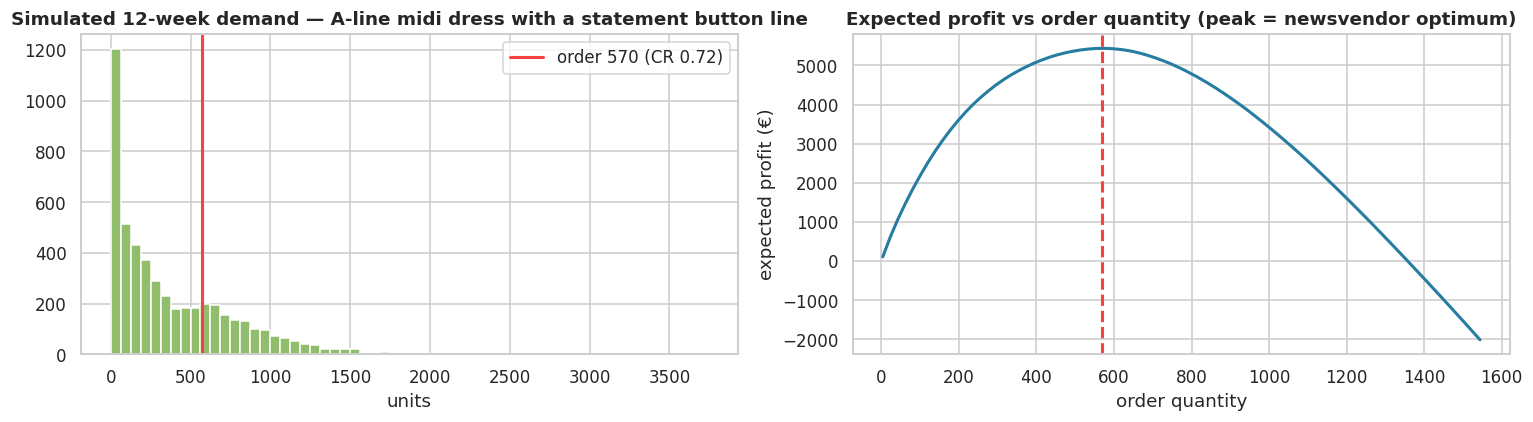

**What it shows:** How many units to order for the top design: the range of possible demand (left) and expected profit at each order size (right).  
**How we made it:** Simulated 5,000 seasons from the random forest's trees, a trend shock and the remaining model error, then ordered at the critical-ratio quantile, which maximises expected profit.

In [48]:
ECON = {"unit_cost": 0.35, "handling": 0.05, "markdown_recovery": {"trend-led": 0.15, "evergreen": 0.30}}
TREND_SHOCK = {"rising": 0.18, "peaking": 0.28, "fading": 0.40, None: 0.15}
N_SIMS = 5000


def tree_totals(row: pd.DataFrame) -> np.ndarray:
    """12-week demand forecast from every tree of the forest (model uncertainty)."""
    X_ = candidate_X(row).to_numpy()
    return np.expm1(np.array([t.predict(X_)[0] for t in rf_full.estimators_])).clip(0) * PANEL_TO_STORE_MULTIPLIER


def newsvendor(totals: np.ndarray, price: float, status, seed: int) -> dict:
    r = np.random.default_rng(seed)
    basis = "trend-led" if status else "evergreen"
    cost, handling = ECON["unit_cost"] * price, ECON["handling"] * price
    salvage = ECON["markdown_recovery"][basis] * price
    cu, co = price - cost, cost + handling - salvage
    cr = cu / (cu + co)
    picks = totals[r.integers(0, len(totals), N_SIMS)]
    tree_sd = float(np.std(np.log1p(totals)))
    rest = float(np.sqrt(max(residual_sigma ** 2 - tree_sd ** 2, 0.15 ** 2)))   # error the trees don't already cover
    shock = r.lognormal(-0.5 * TREND_SHOCK[status] ** 2, TREND_SHOCK[status], N_SIMS)
    noise = r.lognormal(-0.5 * rest ** 2, rest, N_SIMS)
    demand = picks * shock * noise
    q = float(np.quantile(demand, cr))
    sold = np.minimum(demand, q)
    grid = np.linspace(np.quantile(demand, 0.02), np.quantile(demand, 0.99), 80)
    profit_curve = [float(np.mean(cu * np.minimum(demand, g) - co * np.maximum(g - demand, 0))) for g in grid]
    return {"order_units": int(round(q)), "critical_ratio": round(cr, 3), "p10": int(np.quantile(demand, 0.1)),
            "p50": int(np.quantile(demand, 0.5)), "p90": int(np.quantile(demand, 0.9)),
            "stockout_prob": round(float((demand > q).mean()), 3),
            "expected_sell_through": round(float(sold.mean() / q), 3), "expected_leftover": int(np.mean(q - sold)),
            "expected_profit_eur": round(float(np.mean(cu * sold - co * (q - sold))), 0), "markdown_basis": basis,
            "_demand": demand, "_grid": grid, "_curve": profit_curve}


def age_mix(b) -> str:
    ids = products[(products["garment"] == str(b["garment"])) & (products[f"silhouette:{b['silhouette']}"] == 1)]["article_id"]
    if len(ids) < 10:
        ids = products[products["garment"] == str(b["garment"])]["article_id"]
    a_ = age_units[age_units["article_id"].isin(ids) & age_units["age_band"].isin(AGE_BANDS)].groupby("age_band")["units"].sum()
    a_ = (a_ / a_.sum()).reindex(AGE_BANDS).fillna(0)
    return ", ".join(f"{k}: {v:.0%}" for k, v in a_.items())


plan_rows, sims = [], {}
STATUS_RANK = {"rising": 0, "peaking": 1, "fading": 2}
for i, b in briefs.iterrows():
    row = pd.DataFrame([as_feature_row(b, b["colour"])])
    row["trend_kws"] = [matched_keywords(row.at[0, "garment"], row.iloc[0].to_dict())]
    totals = tree_totals(row)
    status = max(b["trend_statuses"], key=STATUS_RANK.get) if b["trend_statuses"] else None
    nv = newsvendor(totals, b["price_eur"], status, seed=int(b["design_id"][1:], 16))
    sims[b["design_id"]] = nv
    spread = (nv["p90"] - nv["p10"]) / max(nv["p50"], 1)
    risk_val = 0.5 * {"rising": 0.15, "peaking": 0.55, None: 0.3}.get(status, 1.0) + 0.5 * spread / 3
    weekly = nv["p50"] * WEEK_PROFILE.loc[str(b["garment"])].to_numpy()
    plan_rows.append({"design_id": b["design_id"], "name": b["name"], "launch_week": str(LAUNCH_WEEK),
                      **{k: v for k, v in nv.items() if not k.startswith("_")},
                      "risk_value": risk_val,
                      "age_mix": age_mix(b), "weekly_forecast": ", ".join(str(int(round(u))) for u in weekly)})
buy_plan = pd.DataFrame(plan_rows)
# Stock risk is relative: the third of briefs with the widest demand range and riskiest trend status are "high"
buy_plan["stock_risk"] = pd.qcut(buy_plan["risk_value"].rank(method="first"), 3, labels=["low", "medium", "high"]).astype(str)
buy_plan = buy_plan.drop(columns="risk_value")
for row in plan_rows:
    row["stock_risk"] = buy_plan.set_index("design_id").loc[row["design_id"], "stock_risk"]
display(buy_plan[["name", "order_units", "p10", "p50", "p90", "critical_ratio", "stockout_prob",
                  "expected_sell_through", "expected_profit_eur", "stock_risk"]])
note("How many units to order for each design, the likely range of demand, and the risk of selling out or overstocking.",
     "Newsvendor model: simulated 5,000 seasons of demand per design and ordered at the quantile that balances lost sales against markdowns.")

top = briefs.iloc[int(briefs["total_score"].idxmax())]
nv = sims[top["design_id"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(nv["_demand"], bins=60, color="#90be6d")
axes[0].axvline(nv["order_units"], color="#f94144", lw=2, label=f"order {nv['order_units']} (CR {nv['critical_ratio']:.2f})")
axes[0].set(title=f"Simulated 12-week demand — {top['name']}", xlabel="units"); axes[0].legend()
axes[1].plot(nv["_grid"], nv["_curve"], color="#277da1", lw=2)
axes[1].axvline(nv["order_units"], color="#f94144", lw=2, ls="--")
axes[1].set(title="Expected profit vs order quantity (peak = newsvendor optimum)", xlabel="order quantity", ylabel="expected profit (€)")
show_fig('How many units to order for the top design: the range of possible demand (left) and expected profit at each order size (right).',
         "Simulated 5,000 seasons from the random forest's trees, a trend shock and the remaining model error, then ordered at the critical-ratio quantile, which maximises expected profit.")

## 12b. AI concept photos for the voting page
Customers vote on photos, not text, so each brief gets a realistic **concept photo in each of its colour options** (the voting page swaps the photo when a shopper taps a colour). Photos are generated with Google's Gemini image model from a prompt built from the brief: garment, cut, length, signature detail, material and exact colour. They are labelled as concept renders, contain no logos or brand names, and are saved to a Drive folder **H&M concept images** with view-only links so the voting page can show them.

One-time setup: get a free API key at [aistudio.google.com/apikey](https://aistudio.google.com/apikey) and add it as a Colab **Secret** named `GEMINI_API_KEY` (🔑 icon on the left, toggle *Notebook access* on). Image generation may need billing enabled on that Google AI Studio project; check its current pricing there. Photos already made are reused on later runs, so you only pay for new designs.

Set `GENERATE_IMAGES = False` in section 1 to skip this step; the voting page then shows a drawn silhouette instead.

In [49]:
IMAGE_MODEL = "gemini-2.5-flash-image"   # Google's image model ("Nano Banana"); change if Google renames it
IMAGE_COLOURS_PER_DESIGN = 4             # photos per design: the chosen colour + up to 3 alternatives
IMG_DIR = OUT_DIR / "concept_images"
IMG_DIR.mkdir(exist_ok=True)
IMG_INDEX_PATH = OUT_DIR / "concept_images.json"
image_index = json.loads(IMG_INDEX_PATH.read_text()) if IMG_INDEX_PATH.exists() else {}   # "design_id|colour" → link

GARMENT_WORD = {"dress": "dress", "top": "top", "jeans": "pair of jeans", "skirt": "skirt"}


def image_prompt(b: dict, colour: str) -> str:
    hex_, _, code = COLOURWAYS[colour]
    colour_txt = f"{colour} (PANTONE {code}, approx. {hex_})" if code else f"{colour} ({hex_})"
    length = f"{b['length']}-length " if b["length"] and b["length"] != "cropped" else ("cropped " if b["length"] == "cropped" else "")
    return (
        f"Photorealistic e-commerce studio photograph of a women's {length}{GARMENT_WORD[str(b['garment'])]}: "
        f"{b['name'].lower()}. Fabric: {b['material']}. Colour: {colour_txt}, rendered accurately. "
        f"Design: a simple, sleek, modern base with exactly one signature detail ({DETAIL_PHRASE[b['detail']]}); "
        f"fashionable, high-street, wearable. Shown on an invisible ghost mannequin, front view, whole garment in frame, "
        f"centred, soft even studio lighting, plain light warm-grey background, crisp fabric texture. "
        f"No people, no faces, no logos, no text, no brand labels, no watermark."
    )


def gemini_key() -> str | None:
    if os.getenv("GEMINI_API_KEY"):
        return os.getenv("GEMINI_API_KEY")
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GEMINI_API_KEY")
        except Exception:
            return None
    return None


def drive_uploader():
    """Upload a PNG to the Drive folder 'H&M concept images' and return a link the voting page can display."""
    from google.colab import auth
    auth.authenticate_user()
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaFileUpload
    svc = build("drive", "v3", cache_discovery=False)
    q = "name='H&M concept images' and mimeType='application/vnd.google-apps.folder' and trashed=false"
    found = svc.files().list(q=q, fields="files(id)").execute().get("files", [])
    folder_id = found[0]["id"] if found else svc.files().create(
        body={"name": "H&M concept images", "mimeType": "application/vnd.google-apps.folder"}, fields="id").execute()["id"]

    def upload(path: Path) -> str:
        f = svc.files().create(body={"name": path.name, "parents": [folder_id]},
                               media_body=MediaFileUpload(str(path), mimetype="image/png"), fields="id").execute()
        svc.permissions().create(fileId=f["id"], body={"type": "anyone", "role": "reader"}).execute()
        return f"https://drive.google.com/thumbnail?id={f['id']}&sz=w1200"
    return upload


def generate_images() -> None:
    key = gemini_key()
    if not GENERATE_IMAGES:
        print("GENERATE_IMAGES is False — skipping concept photos.")
        return
    if not IN_COLAB or not key:
        print("No GEMINI_API_KEY secret found — skipping concept photos (see the setup note above).")
        return
    from google import genai
    client = genai.Client(api_key=key)
    upload = drive_uploader()
    todo = [(b, c) for b in briefs.to_dict("records") for c in ([b["colour"]] + list(b["alt_colours"]))[:IMAGE_COLOURS_PER_DESIGN]
            if f"{b['design_id']}|{c}" not in image_index]
    print(f"{len(todo)} new concept photos to generate ({len(image_index)} already made).")
    for n, (b, colour) in enumerate(todo, start=1):
        k = f"{b['design_id']}|{colour}"
        try:
            resp = client.models.generate_content(model=IMAGE_MODEL, contents=[image_prompt(b, colour)])
            data = next((p.inline_data.data for p in resp.candidates[0].content.parts
                         if getattr(p, "inline_data", None) and p.inline_data.data), None)
            if data is None:
                print(f"  ✗ {b['name']} / {colour}: no image returned"); continue
            path = IMG_DIR / f"{b['design_id']}_{re.sub(r'[^A-Za-z0-9]+', '-', colour)}.png"
            path.write_bytes(data)
            image_index[k] = upload(path)
            IMG_INDEX_PATH.write_text(json.dumps(image_index, indent=1))
            print(f"  ✓ {n}/{len(todo)} {b['name']} / {colour}")
        except Exception as exc:
            msg = str(exc)
            print(f"  ✗ {b['name']} / {colour}: {type(exc).__name__}: {msg[:160]}")
            if "not found" in msg.lower() or "404" in msg:
                names = [m.name for m in client.models.list() if "image" in m.name]
                print(f"Model '{IMAGE_MODEL}' not available. Image models on your key: {names}. "
                      f"Set IMAGE_MODEL to one of them and rerun this cell.")
                return
            if "billing" in msg.lower() or "quota" in msg.lower() or "429" in msg:
                print("Image generation needs billing or more quota on your Google AI Studio project. Skipping the rest.")
                return
        time.sleep(1)


generate_images()
IMAGE_URLS = {b["design_id"]: [image_index.get(f"{b['design_id']}|{c}", "") for c in [b["colour"]] + list(b["alt_colours"])]
              for b in briefs.to_dict("records")}

# Contact sheet of each brief's main photo
shots = [(b, IMG_DIR / f"{b['design_id']}_{re.sub(r'[^A-Za-z0-9]+', '-', b['colour'])}.png") for b in briefs.to_dict("records")]
shots = [(b, p) for b, p in shots if p.exists()]
if shots:
    cols = 4
    rows_ = math.ceil(len(shots) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(14, 4.2 * rows_))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (b, p) in zip(np.ravel(axes), shots):
        ax.imshow(plt.imread(p))
        ax.set_title(f"{b['name']}\n{b['colour']}", fontsize=8.5)
    fig.suptitle("AI concept photos of the design briefs (concept renders, not real products)", y=1.0)
    show_fig("What each design brief could look like, in its recommended colour: the photos shoppers vote on.",
             f"Generated with Google's Gemini image model ({IMAGE_MODEL}) from a prompt built from each brief's cut, "
             "length, signature detail, material and Pantone colour.")
else:
    print("No concept photos yet — the voting page will show a drawn silhouette.")

48 new concept photos to generate (0 already made).
  ✗ A-line midi dress with a statement button line / Langoustino: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on
Image generation needs billing or more quota on your Google AI Studio project. Skipping the rest.
No concept photos yet — the voting page will show a drawn silhouette.


## 13. Publish to the Google Sheet
The notebook writes its results to tabs the business dashboard and voting page read. The `votes` tab is never touched here (only the voting page writes to it). An `image_url` the team pasted in by hand (for example the real Instagram post) is kept over the AI photo, so links already posted on Instagram keep working; designs no longer recommended are marked inactive, not deleted.

In [50]:
def why_text(lines):
    return " | ".join(lines)


designs_new = pd.DataFrame({
    "design_id": briefs["design_id"], "garment": briefs["garment"].astype(str), "name": briefs["name"],
    "description": [f"{'An' if b['material'][0] in 'aeiou' else 'A'} {b['material']} "
                    f"{'pair of jeans' if str(b['garment']) == 'jeans' else str(b['garment'])} in {b['colour']}."
                    + (f" Convertible: {b['conversion']}" if b["multiway"] else "") for b in briefs.to_dict("records")],
    "colours": [", ".join([b["colour"]] + list(b["alt_colours"])) for b in briefs.to_dict("records")],
    "colour_hex": [", ".join(COLOURWAYS[c][0] for c in [b["colour"]] + list(b["alt_colours"])) for b in briefs.to_dict("records")],
    "price_eur": briefs["price_eur"], "multiway": briefs["multiway"], "sustainable": briefs["sustainable"].map({True: "yes", False: "no"}),
    "image_url": [IMAGE_URLS[d][0] for d in briefs["design_id"]],
    "image_urls": [", ".join(IMAGE_URLS[d]) if any(IMAGE_URLS[d]) else "" for d in briefs["design_id"]],
    "active": "TRUE",
})
if len(previous_designs) and "design_id" in previous_designs:
    prev = previous_designs.astype(str).set_index("design_id")
    designs_new = designs_new.set_index("design_id")
    known = designs_new.index.intersection(prev.index)
    if "image_url" in prev:   # keep an image the team pasted in by hand (e.g. the real Instagram post)
        img = prev.loc[known, "image_url"].replace({"nan": ""})
        pasted = (img != "") & ~img.str.startswith("https://drive.google.com/thumbnail")
        designs_new.loc[known, "image_url"] = img.where(pasted, designs_new.loc[known, "image_url"])
    retired = prev.loc[~prev.index.isin(designs_new.index)].reindex(columns=designs_new.columns).fillna("")
    retired["active"] = "FALSE"   # no longer recommended: hidden from the voting page, votes kept
    designs_new = pd.concat([designs_new, retired]).rename_axis("design_id").reset_index()

trend_polls = pd.DataFrame({
    "trend_id": ["T-" + re.sub(r"[^a-z0-9]+", "-", k) for k in trend_table["keyword"]],
    "question": [f"{k.capitalize()}: hot or not?" for k in trend_table["keyword"]],
    "keyword": trend_table["keyword"], "status": trend_table["status"],
})
trend_polls = trend_polls[~trend_table["attribute"].str.contains("baseline")].reset_index(drop=True)

briefs_out = briefs.assign(rank=np.arange(1, len(briefs) + 1), garment=briefs["garment"].astype(str),
                           why=briefs["why"].apply(why_text), hit_probability=briefs["hit_prob"].round(3),
                           sustainable=briefs["sustainable"].map({True: "yes", False: "no"}))[
    ["rank", "design_id", "garment", "name", "silhouette", "length", "detail", "material", "colour", "colour_hex", "pantone",
     "multiway", "conversion", "sustainable", "price_eur", "total_score", "trend_score", "hit_probability", "demand_score",
     "history_score", "novelty_score", "vote_score", "n_votes", "why"]].fillna("")
trends_out = trend_table.merge(trend_votes[["hot_share", "n_votes"]].rename(lambda s: s.replace("T-", ""), axis=0),
                               left_on=trend_table["keyword"].str.replace(r"[^a-z0-9]+", "-", regex=True), right_index=True,
                               how="left").drop(columns="key_0", errors="ignore").fillna("")
colours_out = colour_view.assign(hm_sell_index=colour_view["hm_sell_index"].round(2)).fillna("")
vote_summary = design_votes.reset_index().rename(columns={"index": "item_id"}).round(3) if len(design_votes) else pd.DataFrame(
    columns=["item_id", "n_votes", "approval", "wilson_low", "avg_rating", "price_yes"])
model_report = pd.concat([
    holdout_results.reset_index().assign(task="weekly demand (regression)"),
    cls_results.reset_index().assign(task="hit classifier")], ignore_index=True).round(3).fillna("")
run_info = pd.DataFrame([
    ("as_of", str(AS_OF)), ("launch_week", str(LAUNCH_WEEK)), ("sales_history", f"{DATA_START:%Y-%m-%d} to {DATA_END:%Y-%m-%d}"),
    ("launches_modelled", f"{len(products):,}"), ("candidates_generated", f"{len(cands):,}"),
    ("votes_used", f"{len(votes):,}"), ("demand_model", "Random forest (per-tree paths feed the stock simulation)"),
    ("best_demand_model_on_holdout", best_name), ("best_hit_classifier", best_cls),
    ("trend_sources", "Google Trends (monthly, worldwide); Pantone COTY 2026, AW26 & SS27 NYFW reports"),
    ("data_source", "H&M Personalized Fashion Recommendations (Kaggle)"),
    ("note", "Independent concept project; not affiliated with H&M. Euro prices and unit economics are assumptions."),
    ("updated_at", datetime.now().strftime("%Y-%m-%d %H:%M")),
], columns=["key", "value"])

OUTPUT_TABS = {"designs": designs_new, "trend_polls": trend_polls, "briefs": briefs_out, "buy_plan": buy_plan,
               "trends": trends_out, "colours": colours_out, "vote_summary": vote_summary, "model_report": model_report,
               "run_info": run_info}


def write_tab(sh, name: str, df: pd.DataFrame) -> None:
    df = df.copy()
    for c in df.columns:
        df[c] = df[c].map(lambda v: "" if v is None or (isinstance(v, float) and np.isnan(v)) else
                          (round(v, 4) if isinstance(v, float) else (str(v) if not isinstance(v, (int, np.integer)) else int(v))))
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
    if sh is None:
        return
    try:
        ws = sh.worksheet(name)
    except Exception:
        ws = sh.add_worksheet(title=name, rows=max(len(df) + 10, 50), cols=max(len(df.columns) + 2, 10))
    ws.clear()
    ws.update(range_name="A1", values=[df.columns.tolist()] + df.astype(object).values.tolist())


for name, df in OUTPUT_TABS.items():
    write_tab(sheet, name, df)
print(("Published to the Google Sheet: " if sheet else "Saved locally (no SHEET_URL set): ") + ", ".join(OUTPUT_TABS))
print(f"Local copies in {OUT_DIR}")

Published to the Google Sheet: designs, trend_polls, briefs, buy_plan, trends, colours, vote_summary, model_report, run_info
Local copies in /content/drive/MyDrive/hm_design_intelligence/outputs


## 14. Summary
The cell below prints what the business dashboard will show. Rerun the notebook whenever new votes come in, or each week to refresh Google Trends: briefs, scores and order quantities update and the dashboard picks them up automatically.

In [51]:
print(f"As of {AS_OF}: {len(trend_table)} tracked trends — "
      f"{(trend_table.status == 'rising').sum()} rising, {(trend_table.status == 'peaking').sum()} peaking, "
      f"{(trend_table.status == 'fading').sum()} fading.")
print(f"Demand model: {best_name} best on holdout (R² on log sales {holdout_results.loc[best_name, 'R² (log)']:.2f} vs baseline "
      f"{holdout_results.iloc[0]['R² (log)']:.2f}; WAPE {holdout_results.loc[best_name, 'WAPE']:.2f} vs "
      f"{holdout_results.iloc[0]['WAPE']:.2f}). Hit classifier: {best_cls}, AUC {cls_results.loc[best_cls, 'ROC AUC']:.2f}.")
print(f"{len(briefs)} briefs, {sum(bool(m) for m in briefs['multiway'])} convertible, {int(briefs['sustainable'].sum())} sustainable; "
      f"total first order {buy_plan['order_units'].sum():,} units for launch w/c {LAUNCH_WEEK}.\n")
for b, p in zip(briefs.to_dict("records"), plan_rows):
    print(f"• {b['name']} — {b['colour']}, {b['material']}, €{b['price_eur']:.2f} · score {b['total_score']:.0f} · "
          f"make {p['order_units']:,} ({p['stock_risk']} risk)")

As of 2026-11-07: 26 tracked trends — 6 rising, 12 peaking, 8 fading.
Demand model: Random forest best on holdout (R² on log sales 0.20 vs baseline -0.05; WAPE 0.67 vs 0.74). Hit classifier: Random forest, AUC 0.73.
12 briefs, 4 convertible, 4 sustainable; total first order 5,218 units for launch w/c 2027-01-25.

• A-line midi dress with a statement button line — Langoustino, organic linen, €45.99 · score 98 · make 570 (medium risk)
• Fitted midi dress with a smocked bodice — Tarragon, viscose crêpe, €37.99 · score 82 · make 389 (medium risk)
• Slip mini dress with a ruffle edge — Cloud Dancer, cotton jersey, €34.99 · score 68 · make 336 (high risk)
• Oversized top with a statement button line — Langoustino, organic linen, €26.99 · score 92 · make 458 (low risk)
• Fitted top with corset seaming — Tarragon, viscose crêpe, €21.99 · score 88 · make 470 (high risk)
• Wrap top with a lace trim — Chili Pepper, cotton jersey, €19.99 · score 84 · make 437 (medium risk)
• Barrel-leg jeans with 

## 15. Limitations (worth saying in the presentation)
- **Sales history is 2018–2020.** It's the only public item-level H&M sales data. The model learns how attributes, price, season and search interest drive demand from it, and is then fed *today's* Google Trends and Pantone signals. Tastes shift, so customer votes and fresh trend data matter.
- **Lockdown 2020** distorts part of the history; a lockdown flag absorbs it, but the most recent holdout launches still sit near that period.
- **Units are H&M's Kaggle customer panel**, not total store sales. Use `PANEL_TO_STORE_MULTIPLIER` to scale.
- **Prices are anonymised** in the Kaggle data, so the model uses relative price; euro prices and unit economics in the briefs are stated assumptions.
- **Design attributes come from text rules** on product names and descriptions; a word like "wide" can occasionally describe a strap rather than the leg.
- **Google Trends** is a relative index and can rate-limit; `pytrends` is an unofficial client.
- **Pantone** has no data feed; its palettes are entered by hand each season.
- **Votes are self-selected** (people who follow the account and tap the link), so they show direction, not a representative survey. Each anonymous voter counts once per design.

## 16. Word report: every chart and table in one document
Builds **`HM_Design_Intelligence_Report.docx`** (no code, just results) and saves it next to the other outputs in your Drive folder (`hm_design_intelligence/outputs`). In Colab it also offers the file as a download.

In [52]:
from docx import Document
from docx.enum.section import WD_ORIENT
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Cm, Pt, RGBColor

INK, MUTED, ACCENT = RGBColor(0x1D, 0x1C, 0x1A), RGBColor(0x6B, 0x68, 0x62), RGBColor(0xC8, 0x10, 0x2E)


def shade(cell, hex_fill: str) -> None:
    tc_pr = cell._tc.get_or_add_tcPr()
    shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear"); shd.set(qn("w:color"), "auto"); shd.set(qn("w:fill"), hex_fill)
    tc_pr.append(shd)


def add_table(doc, df: pd.DataFrame, widths_cm: list[float] | None = None, font_pt: float = 8) -> None:
    t = doc.add_table(rows=1, cols=len(df.columns))
    t.style = "Table Grid"
    t.alignment = WD_TABLE_ALIGNMENT.CENTER
    for i, col in enumerate(df.columns):
        cell = t.rows[0].cells[i]
        cell.text = ""
        run = cell.paragraphs[0].add_run(str(col)); run.bold = True; run.font.size = Pt(font_pt)
        shade(cell, "EFECE6")
    for _, row in df.iterrows():
        cells = t.add_row().cells
        for i, v in enumerate(row):
            cells[i].text = ""
            run = cells[i].paragraphs[0].add_run("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
            run.font.size = Pt(font_pt)
    if widths_cm:
        t.autofit = False
        for i, w in enumerate(widths_cm):
            t.columns[i].width = Cm(w)
        for row in t.rows:
            for i, w in enumerate(widths_cm):
                row.cells[i].width = Cm(w)
    doc.add_paragraph()


def heading(doc, text: str, level: int = 1) -> None:
    h = doc.add_heading(text, level=level)
    for r in h.runs:
        r.font.color.rgb = INK


def explain(doc, about: str, how: str, label: str = "") -> None:
    """Two short lines under a chart or table: what it shows, and how we made it."""
    for title, text in ((f"{label}What it shows: " if label else "What it shows: ", about), ("How we made it: ", how)):
        p = doc.add_paragraph()
        p.paragraph_format.space_after = Pt(1)
        r = p.add_run(title); r.bold = True; r.font.size = Pt(9); r.font.color.rgb = INK
        r = p.add_run(text); r.font.size = Pt(9); r.font.color.rgb = MUTED
    doc.add_paragraph()


doc = Document()
sec = doc.sections[0]
sec.left_margin = sec.right_margin = Cm(1.8)
sec.top_margin = sec.bottom_margin = Cm(1.6)
doc.styles["Normal"].font.name = "Calibri"
doc.styles["Normal"].font.size = Pt(10.5)

# Title page
t = doc.add_paragraph()
r = t.add_run("H&M Design & Demand Intelligence"); r.bold = True; r.font.size = Pt(26); r.font.color.rgb = INK
t = doc.add_paragraph()
r = t.add_run("Results report: what to design, why, and how many to make"); r.font.size = Pt(14); r.font.color.rgb = ACCENT
doc.add_paragraph(f"Generated {datetime.now():%d %B %Y} · analysis as of {AS_OF:%d %B %Y} · briefs launch week of {LAUNCH_WEEK:%d %B %Y}")
p = doc.add_paragraph()
r = p.add_run("Independent concept project, not affiliated with or endorsed by H&M. The sales data is H&M Group's public "
              "Kaggle release; euro prices and unit economics are stated assumptions.")
r.italic = True; r.font.size = Pt(9); r.font.color.rgb = MUTED

# 1. Summary
heading(doc, "1. Summary")
n_rising = int((trend_table.status == "rising").sum())
best_r2 = holdout_results.loc[best_name, "R² (log)"]
for line in [
    f"Data: {len(products):,} real H&M product launches (women's dresses, tops, jeans and skirts) from "
    f"{DATA_START:%B %Y} to {DATA_END:%B %Y}, built from 31 million transactions; Google search interest for "
    f"{len(trend_table)} fashion keywords (2018 to today); Pantone's Colour of the Year 2026 and NYFW AW26 and SS27 "
    f"colour reports; {len(votes):,} customer votes.",
    f"Trends: {n_rising} of {len(trend_table)} tracked keywords are rising year on year; "
    f"{int((trend_table.status == 'fading').sum())} are fading; designs tied mostly to fading trends are excluded from the briefs.",
    f"Demand model: {best_name} predicts a new product's 12-week sales with R² = {best_r2:.2f} on log sales for launches "
    f"it never saw (baseline {holdout_results.iloc[0]['R² (log)']:.2f}).",
    f"Hit classifier: {best_cls} identifies likely top-25% sellers with ROC AUC = {cls_results.loc[best_cls, 'ROC AUC']:.2f} "
    f"(0.5 = guessing).",
    f"Output: {len(briefs)} design briefs chosen from {len(cands):,} generated candidates, "
    f"{sum(bool(m) for m in briefs['multiway'])} convertible and {int(briefs['sustainable'].sum())} in sustainable materials, "
    f"with a total first order of {buy_plan['order_units'].sum():,} units.",
]:
    doc.add_paragraph(line, style="List Bullet")

# 2. Method
heading(doc, "2. Data and method")
add_table(doc, pd.DataFrame([
    ("H&M sales (Kaggle)", "Weekly units per product, launch dates, prices, product descriptions, customer ages", "Demand model, hit classifier, attribute history"),
    ("Google Trends", "Monthly worldwide search interest per keyword, 2018 to today", "Trend score, demand-model feature, trend status"),
    ("Pantone", "COTY 2026, NYFW AW26 and SS27 palettes mapped to H&M colour groups", "Colourway choice"),
    ("Customer votes", "Ratings, colour picks and price answers from the voting page", "Vote score, colour choice"),
], columns=["Source", "What it contains", "Used for"]), widths_cm=[3.5, 8.5, 5.5])
explain(doc, "The four data sources behind the tool and what each one feeds.",
        "H&M data downloaded from Kaggle, Google Trends through pytrends, Pantone entered by hand, votes read from the Google Sheet.")
doc.add_paragraph(
    "Each candidate design combines a simple base (garment, silhouette, length, fabric) with one signature detail, "
    "a colourway and optional convertible and sustainable versions. Candidates are scored on trend (25%), hit "
    "probability (20%), forecast demand (15%), H&M sales history of their attributes (15%), customer votes (15%) and "
    "novelty (10%). A balanced set of 12 is chosen with variety rules and quotas for convertible and sustainable "
    "pieces. Order quantities come from a newsvendor model on 5,000 simulated seasons per design.")

# 3. Briefs
heading(doc, "3. Design briefs")
bt = briefs.assign(
    garment=briefs["garment"].astype(str),
    colour_txt=[f"{c} ({'PANTONE ' + p if p else 'core'})" for c, p in zip(briefs["colour"], briefs["pantone"])],
    conv=[m or "—" for m in briefs["multiway"]],
    sust=briefs["sustainable"].map({True: "yes", False: "no"}),
    price=briefs["price_eur"].map(lambda v: f"€{v:.2f}"),
    score=briefs["total_score"].map(lambda v: f"{v:.0f}"),
    hit=briefs["hit_prob"].map(lambda v: f"{v:.0%}"))
add_table(doc, bt[["garment", "name", "colour_txt", "material", "conv", "sust", "price", "score", "hit"]].rename(columns={
    "garment": "Garment", "name": "Design", "colour_txt": "Colour", "material": "Material", "conv": "Convertible",
    "sust": "Sustainable", "price": "Price", "score": "Score", "hit": "Hit prob."}),
    widths_cm=[1.4, 4.6, 2.9, 2.7, 2.3, 1.5, 1.3, 1.0, 1.0])
explain(doc, "The design briefs: what to make, in which colour and material, at what price, with its total score and chance of being a top seller.",
        f"Generated {len(cands):,} candidate designs from building blocks, scored each with the models, trends, Pantone and votes, "
        "and picked a balanced set with variety rules and convertible/sustainable quotas.")
heading(doc, "Why each design was chosen", level=2)
for b in briefs.to_dict("records"):
    p = doc.add_paragraph()
    r = p.add_run(f"{b['name']} — {b['colour']}, {b['material']}"); r.bold = True
    if b["multiway"]:
        doc.add_paragraph(f"Convertible ({b['multiway']}): {b['conversion']}", style="List Bullet")
    for line in b["why"]:
        doc.add_paragraph(line, style="List Bullet")

# 4. Buy plan
heading(doc, "4. Buy plan")
add_table(doc, buy_plan[["name", "order_units", "p10", "p50", "p90", "stockout_prob", "expected_sell_through",
                         "expected_profit_eur", "stock_risk"]].assign(
    stockout_prob=lambda d: d["stockout_prob"].map(lambda v: f"{v:.0%}"),
    expected_sell_through=lambda d: d["expected_sell_through"].map(lambda v: f"{v:.0%}"),
    expected_profit_eur=lambda d: d["expected_profit_eur"].map(lambda v: f"€{v:,.0f}")).rename(columns={
    "name": "Design", "order_units": "Order", "p10": "p10", "p50": "p50", "p90": "p90", "stockout_prob": "Stock-out",
    "expected_sell_through": "Sell-through", "expected_profit_eur": "Exp. profit", "stock_risk": "Risk"}),
    widths_cm=[5.6, 1.3, 1.1, 1.1, 1.1, 1.6, 1.8, 2.0, 1.4])
explain(doc, "How many units to order for each design, the likely demand range (p10–p90 covers 80% of outcomes), "
             "the chance of selling out, expected sell-through and profit.",
        f"Newsvendor model on 5,000 simulated seasons per design; units are on the H&M Kaggle customer-panel scale "
        f"× {PANEL_TO_STORE_MULTIPLIER:g}, and prices and costs are stated assumptions.")

# 5. Models
heading(doc, "5. Model results")
mr = holdout_results.reset_index().round(3).fillna("—")
add_table(doc, mr, widths_cm=None)
explain(doc, "How accurately each demand model predicts a new product's 12-week sales (higher R², lower MAE and WAPE are better).",
        "Trained on the oldest 80% of launches and tested on the newest 20%, which the models never saw; the cross-validation "
        "column repeats this over 3 time-ordered folds.")
add_table(doc, cls_results.reset_index().round(3))
explain(doc, "How well each classifier spots future best-sellers (AUC 0.5 = guessing, 1.0 = perfect).",
        "A hit is a top-25% product of its garment type by first-8-week sales; models were trained on older launches and "
        "tested on the newest 20%.")

# 6. Trends
heading(doc, "6. Trend signals")
add_table(doc, trend_table[["keyword", "attribute", "status", "yoy_change_pct", "at_launch", "lifecycle"]].rename(columns={
    "keyword": "Keyword", "attribute": "Design attribute", "status": "Status", "yoy_change_pct": "YoY %",
    "at_launch": "At launch (×avg)", "lifecycle": "Lifecycle cluster"}), widths_cm=[3.6, 4.2, 1.8, 1.6, 2.6, 2.8])
explain(doc, "Each tracked fashion keyword: whether it is rising, peaking or fading, its year-on-year change, its projected "
             "interest at launch (1.00 = a normal month) and its lifecycle cluster.",
        "Monthly Google Trends data, deseasonalised and projected forward with a damped trend; lifecycle clusters from k-means.")

# 7. Charts
heading(doc, "7. Charts")
for i, (about, (path, how)) in enumerate(REPORT_FIGS.items(), start=1):
    if not Path(path).exists():
        continue
    from PIL import Image
    with Image.open(path) as im:
        natural_cm = im.width / 150 * 2.54          # charts are saved at 150 dpi
    doc.add_picture(str(path), width=Cm(min(17, natural_cm * 0.75)))
    doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
    explain(doc, about, how, label=f"Figure {i}. ")

# 8. Limitations
heading(doc, "8. Limitations")
for line in [
    "Sales history covers 2018–2020, the only public item-level H&M sales data; today's trends enter through Google Trends, Pantone and customer votes.",
    "The 2020 lockdown distorts part of the history; a lockdown feature absorbs it, but the most recent holdout launches sit near that period.",
    "Units are H&M's Kaggle customer panel, not total store sales; prices in the data are anonymised, so euro prices and costs are assumptions.",
    "Design attributes are extracted from product names and descriptions with text rules, which occasionally misread a word.",
    "Google Trends is a relative index; Pantone palettes are entered by hand each season.",
    "Customer votes are self-selected (people who follow the account and tap the link), so they show direction rather than a representative survey.",
]:
    doc.add_paragraph(line, style="List Bullet")

REPORT_PATH = OUT_DIR / "HM_Design_Intelligence_Report.docx"
doc.save(REPORT_PATH)
print(f"Report saved: {REPORT_PATH}  ({len(REPORT_FIGS)} charts, {REPORT_PATH.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(REPORT_PATH))

Report saved: /content/drive/MyDrive/hm_design_intelligence/outputs/HM_Design_Intelligence_Report.docx  (18 charts, 2.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>